# Project1: Recommendation for Movie Company

## 1. Data Acquisition & Preparation

In [ ]:

import warnings
warnings.filterwarnings("ignore")

In [ ]:
from google.colab import drive
drive.mount("/content/drive")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
import pandas as pd

import pandas as pd

df = pd.read_csv(
    "/content/drive/MyDrive/Project1: Recommendation for Movie Company/netflix_movies_detailed_up_to_2025.csv"
)

df.head()
#df = pd.read_csv('netflix_movies_detailed_up_to_2025.csv')
#df.head()

,show_id,type,title,director,cast,country,date_added,release_year,rating,duration,genres,language,description,popularity,vote_count,vote_average,budget,revenue
0,10192,Movie,Shrek Forever After,Mike Mitchell,"Mike Myers, Eddie Murphy, Cameron Diaz, Antoni...",United States of America,2010-05-16,2010,6.380,NaN,"Comedy, Adventure, Fantasy, Animation, Family",en,A bored and domesticated Shrek pacts with deal...,203.893,7449,6.380,165000000,752600867
1,27205,Movie,Inception,Christopher Nolan,"Leonardo DiCaprio, Joseph Gordon-Levitt, Ken W...","United Kingdom, United States of America",2010-07-15,2010,8.369,NaN,"Action, Science Fiction, Adventure",en,"Cobb, a skilled thief who commits corporate es...",156.242,37119,8.369,160000000,839030630
2,12444,Movie,Harry Potter and the Deathly Hallows: Part 1,David Yates,"Daniel Radcliffe, Emma Watson, Rupert Grint, T...","United Kingdom, United States of America",2010-11-17,2010,7.744,NaN,"Adventure, Fantasy",en,"Harry, Ron and Hermione walk away from their l...",121.191,19327,7.744,250000000,954305868
3,38757,Movie,Tangled,"Byron Howard, Nathan Greno","Mandy Moore, Zachary Levi, Donna Murphy, Ron P...",United States of America,2010-11-24,2010,7.600,NaN,"Animation, Family, Adventure",en,"Feisty teenager Rapunzel, who has long and mag...",111.762,11638,7.600,260000000,592461732
4,10191,Movie,How to Train Your Dragon,"Chris Sanders, Dean DeBlois","Jay Baruchel, Gerard Butler, Craig Ferguson, A...",United States of America,2010-03-18,2010,7.800,NaN,"Fantasy, Adventure, Animation, Family",en,As the son of a Viking leader on the cusp of m...,110.044,13259,7.800,165000000,494879471


In [ ]:
import pandas as pd
df = pd.read_csv('netflix_movies_detailed_up_to_2025.csv')

In [ ]:
print("Dataset shape:", df.shape)
print("\n")

print(df.info())

Dataset shape: (16000, 18)


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 16000 entries, 0 to 15999
Data columns (total 18 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   show_id       16000 non-null  int64  
 1   type          16000 non-null  object 
 2   title         16000 non-null  object 
 3   director      15868 non-null  object 
 4   cast          15796 non-null  object 
 5   country       15534 non-null  object 
 6   date_added    16000 non-null  object 
 7   release_year  16000 non-null  int64  
 8   rating        16000 non-null  float64
 9   duration      0 non-null      float64
 10  genres        15893 non-null  object 
 11  language      16000 non-null  object 
 12  description   15868 non-null  object 
 13  popularity    16000 non-null  float64
 14  vote_count    16000 non-null  int64  
 15  vote_average  16000 non-null  float64
 16  budget        16000 non-null  int64  
 17  revenue       16000 non-null  int64  
dt

In [ ]:
# Description of each column
print(df.describe(include='all'))

             show_id   type  title     director  \
count   1.600000e+04  16000  16000        15868   
unique           NaN      1  15485         9508   
top              NaN  Movie   Eden  Tyler Perry   
freq             NaN  16000      6           20   
mean    5.266582e+05    NaN    NaN          NaN   
std     3.794427e+05    NaN    NaN          NaN   
min     1.890000e+02    NaN    NaN          NaN   
25%     2.257258e+05    NaN    NaN          NaN   
50%     4.468170e+05    NaN    NaN          NaN   
75%     7.739808e+05    NaN    NaN          NaN   
max     1.440471e+06    NaN    NaN          NaN   

                                                     cast  \
count                                               15796   
unique                                              15639   
top     Wasabi Mizuta, Megumi Oohara, Yumi Kakazu, Sub...   
freq                                                   10   
mean                                                  NaN   
std                  

### Handle Missing Values

1. drop column "duration" because all of them are null
2. drop the data which their genres and description are both null
3. fill the missing value of genres by the key words in the description
4. fill "lack of description" into the missing value of the description
5. delete the data if they lack of director or cast or country


In [ ]:
df.dropna(how='all')
df.isnull().sum()

show_id             0
type                0
title               0
director          132
cast              204
country           466
date_added          0
release_year        0
rating              0
duration        16000
genres            107
language            0
description       132
popularity          0
vote_count          0
vote_average        0
budget              0
revenue             0
dtype: int64

In [ ]:
# drop column "duration" because all of them are null
df = df.drop(columns=['duration'])
print("Dataset shape:", df.shape)

Dataset shape: (16000, 17)


In [ ]:
df['genres'].unique().tolist()

['Comedy, Adventure, Fantasy, Animation, Family',
 'Action, Science Fiction, Adventure',
 'Adventure, Fantasy',
 'Animation, Family, Adventure',
 'Fantasy, Adventure, Animation, Family',
 'Drama, Thriller, Mystery',
 'Action, Adventure, Drama, Family',
 'Adventure, Action, Science Fiction',
 'Comedy',
 'Drama, Romance',
 'Animation, Family, Comedy',
 'Adventure, Fantasy, Drama, Romance',
 'Family, Fantasy, Adventure',
 'Crime, Horror, Thriller',
 'Action, Thriller, Crime, Drama',
 'Drama',
 'Romance, Drama',
 'Adventure, Fantasy, Family',
 'Crime, Drama, Thriller',
 'Science Fiction, Action, Thriller',
 'Animation, Action, Comedy, Family, Science Fiction',
 'Adventure, Family, Fantasy',
 'Thriller, Adventure, Action',
 'Adventure, Fantasy, Action',
 'Drama, Thriller, Horror',
 'Action, Crime',
 'Action, Crime, Western, Comedy, Drama',
 'Action, Crime, Thriller',
 'Action, Adventure, Fantasy',
 'Action, Comedy, Crime, Thriller',
 'Drama, Action, Crime',
 'Action, Comedy, Romance',
 'Hor

In [ ]:
# drop the data which their genres and description are both null
df.dropna(subset=['genres', 'description'], how='all', inplace=True)
df.shape

(15983, 17)

In [ ]:
pd.set_option('display.max_colwidth', None)
pd.set_option('display.max_rows', 200)
df[df['genres'].isna()][['show_id', 'title', 'description']]

,show_id,title,description
74,534643,Tabu,"Young musician goes on vacation with his family. He meets an older woman there, they fall in love and spend a passionate night together. The next day, his family has something shocking to tell him."
2480,305817,YtF,"Imagine if Jesus Christ had never existed until this present time. How would He interact in todays society? How would He respond to the current day issues? He would respond the same way He did over 2000 years ago. Watch this well known story unfold with a fresh, new context and become a believer that regardless of the time, location or any other circumstances, Jesus Christs words and actions still stand firm and will continue until His return. YTF is taken from Hebrews 13:8, which the NIV Bible states Jesus Christ is the same Yesterday, Today and Forever."
2844,257003,A Porn Star Is Born,"Beautiful Aliana Love moves to Los Angeles with dreams of becoming a star, but quickly realizes that, in Hollywood, you are either on the plate or in front of it. Financial woes force a reluctant but desperate Aliana into the seedy world of adult films, and porn king John Goldman is only too happy to exploit her looks and innocence - turning her into the biggest, X-rated contract star in years."
2987,154181,Heaven In Your Eyes,"Pepe, a very talented singer, but not very sure about himself, is going to sing on FICLA and he is very nervous. The same day of the contest, he meets Abril, a very beautiful astronomer. Pepe thinks she is the perfect woman for him, because there is a lot of chemistry between both of them, and he thinks it’s love at first sight. Nevertheless she is getting married that night. What could Pepe do in a very short time? Which plans does the destiny have for him?"
3912,158455,An Afghan Love Story,"It’s snowing in Kabul, and gregarious waiter Mustafa charms a pretty student named Wajma. The pair begin a clandestine relationship—they’re playful and passionate but ever mindful of the societal rules they are breaking. After Wajma discovers she is pregnant, her certainty that Mustafa will marry her falters, and word of their dalliance gets out. Her father must decide between his culturally held right to uphold family honor and his devotion to his daughter."
4623,946620,XXX,"Found footage short film piece conceived through the articulation of appropriated and recycled film fragments to conform a unified sex scene composed by different bodies, ambients and characters. Structuring a begging, a climax and an ending. It is an inquiry into the construction of (self) identity, gender issues, memory, and the process of rewriting/reimagining personal recollections. It was assembled as a chapter for an autobiographical long film called An Appropriated Self-Portrait, edited using a fragmentary structure that relies on a linear narrative."
5809,359892,Twilight,"Alicia, a circus clown, dreams of being an actress. When the circus arrives in a remote village she meets Abelito, a boy with a skin disorder that prevents him from going out in the sun. As Abelito looks forward to the circus, Alicia anxiously awaits news from Havana about a casting."
6091,1201898,こくまろオッパイ かきまぜられた私,"This woman melts when gently simmered... Full of volume! A hearty meal... The purpose of the sponsor was my wife's breasts!? This work is an erotic drama that depicts a couple who abandon their mother with dementia due to the hardships of life, and a couple whose wife's body kills a sponsor who is manipulated by a mysterious fate."
6210,1100848,Zetsu-Rin! Invisible Hentai Man,"The protagonist, who uses the 'Elixir of Iga' for self-interest and spends his days in the sake pond meat forest, makes a mistake in using the medicine and becomes an invisible human. An erotic comedy that is bound to burst into laughter about the true love of a man who has lost everything and finally finds true love with a woman of destiny, full of naughty perspectives."
6229,457697,XXXXXXX,A tarot card reading as a starting point. A disruptive

In [ ]:
# handling missing value of genres by description

def define_genre(description):
    if pd.isna(description):
        return "Drama"

    desc = str(description).lower()

    if any(word in desc for word in ["musician", "singer", "song", "music"]):
        return "Music"
    elif any(word in desc for word in ["love", "passion", "romantic", "marry"]):
        return "Romance, Drama"
    elif any(word in desc for word in ["comedy", "funny", "laugh", "clown"]):
        return "Comedy"
    elif any(word in desc for word in ["space", "future", "alien", "science fiction"]):
        return "Science Fiction"
    elif any(word in desc for word in ["documentary", "short film", "true story"]):
        return "Documentary"
    elif any(word in desc for word in ["scary", "horror", "ghost", "dark"]):
        return "Horror"
    elif any(word in desc for word in ["erotic", "porn", "adult", "hentai", "xxx"]):
        return "Adult"
    elif any(word in desc for word in ["action", "battle", "fight"]):
        return "Action"

    return "Drama"

# Apply it to fill the NaNs
mask = df['genres'].isna()
df.loc[mask, 'genres'] = df.loc[mask, 'description'].apply(define_genre)

# check
print(f"Missing genres remaining: {df['genres'].isna().sum()}")


Missing genres remaining: 0


In [ ]:
# fill missing value of description to "lack of description"

df['description'] = df['description'].fillna("lack of description")

In [ ]:
# delete the data if they lack of director or cast or country

df.dropna(subset=['director', 'cast', 'country'], how='any', inplace=True)

In [ ]:
# check the null counts again
print(df.isnull().sum())
print(f"New dataset shape: {df.shape}")
print("\n")
pd.reset_option('display.max_colwidth')
df.head()

show_id         0
type            0
title           0
director        0
cast            0
country         0
date_added      0
release_year    0
rating          0
genres          0
language        0
description     0
popularity      0
vote_count      0
vote_average    0
budget          0
revenue         0
dtype: int64
New dataset shape: (15324, 17)




,show_id,type,title,director,cast,country,date_added,release_year,rating,genres,language,description,popularity,vote_count,vote_average,budget,revenue
0,10192,Movie,Shrek Forever After,Mike Mitchell,"Mike Myers, Eddie Murphy, Cameron Diaz, Antoni...",United States of America,2010-05-16,2010,6.380,"Comedy, Adventure, Fantasy, Animation, Family",en,A bored and domesticated Shrek pacts with deal...,203.893,7449,6.380,165000000,752600867
1,27205,Movie,Inception,Christopher Nolan,"Leonardo DiCaprio, Joseph Gordon-Levitt, Ken W...","United Kingdom, United States of America",2010-07-15,2010,8.369,"Action, Science Fiction, Adventure",en,"Cobb, a skilled thief who commits corporate es...",156.242,37119,8.369,160000000,839030630
2,12444,Movie,Harry Potter and the Deathly Hallows: Part 1,David Yates,"Daniel Radcliffe, Emma Watson, Rupert Grint, T...","United Kingdom, United States of America",2010-11-17,2010,7.744,"Adventure, Fantasy",en,"Harry, Ron and Hermione walk away from their l...",121.191,19327,7.744,250000000,954305868
3,38757,Movie,Tangled,"Byron Howard, Nathan Greno","Mandy Moore, Zachary Levi, Donna Murphy, Ron P...",United States of America,2010-11-24,2010,7.600,"Animation, Family, Adventure",en,"Feisty teenager Rapunzel, who has long and mag...",111.762,11638,7.600,260000000,592461732
4,10191,Movie,How to Train Your Dragon,"Chris Sanders, Dean DeBlois","Jay Baruchel, Gerard Butler, Craig Ferguson, A...",United States of America,2010-03-18,2010,7.800,"Fantasy, Adventure, Animation, Family",en,As the son of a Viking leader on the cusp of m...,110.044,13259,7.800,165000000,494879471


### Encode Categorical Features

- Only keep 20 directors who's movie count is the top 20, others as 'Other'
- Only keep 20 cast who's movie count is the top 20, others as 'Other'
- Use One-Hot Encoding for language, director (after grouping), cast(after grouping), and genres.  
- Since genres contains multiple values in one string (e.g., "Comedy, Adventure, Fantasy, Animation, Family"), we use `str.get_dummies` to split them into individual binary columns.

In [ ]:
# Grouping directors: Keep top 20 by movie count, others as 'Other'
top_20_directors = df['director'].value_counts().nlargest(20).index
df['director_grouped'] = df['director'].apply(lambda x: x if x in top_20_directors else 'Other')

print(df['director_grouped'].value_counts())
print(f"\nUnique directors after grouping: {df['director_grouped'].nunique()}")

director_grouped
Other                 15063
Tyler Perry              20
Roel Reiné               15
Steven Soderbergh        15
Sean McNamara            15
Choi Woo-seong           14
Sam Liu                  13
Ernie Barbarash          13
Jesse V. Johnson         13
Don Michael Paul         13
Richard Kim              13
Takashi Miike            12
Sion Sono                12
Alex Zamm                12
David Gordon Green       12
Steven C. Miller         12
Jared Cohn               12
Peter Sullivan           12
Ridley Scott             11
Antoine Fuqua            11
Shinsuke Sato            11
Name: count, dtype: int64

Unique directors after grouping: 21


In [ ]:
# Grouping cast: Keep top 20 by movie count, others as 'Other'
from sklearn.preprocessing import MultiLabelBinarizer

df['cast_split'] = df['cast'].fillna('Unknown').str.split(', ')
top_20_actors = df.explode('cast_split')['cast_split'].value_counts().nlargest(20).index.tolist()

def group_cast_list(actor_list):
    main_cast = [actor for actor in actor_list if actor in top_20_actors]
    return main_cast[:5] if len(main_cast) > 0 else ['Other']

df['cast_list'] = df['cast_split'].apply(group_cast_list)

mlb = MultiLabelBinarizer()
cast_encoded = pd.DataFrame(mlb.fit_transform(df['cast_list']),
                            columns=mlb.classes_,
                            index=df.index).add_prefix('cast_')

In [ ]:
# Encode 'language'
lang_dummies = pd.get_dummies(df['language'], prefix='lang')

# Encode 'director' (Using the grouped column)
director_dummies = pd.get_dummies(df['director_grouped'], prefix='director')

# Encode 'genres'
genre_dummies = df['genres'].str.get_dummies(sep=', ').add_prefix('genres_')

# Combine them
df_processed = pd.concat([df, lang_dummies, director_dummies, cast_encoded, genre_dummies], axis=1)

# Drop the original text columns and the intermediate grouped column
df_processed = df_processed.drop(['language', 'director', 'cast', 'genres'], axis=1)
df_processed

,show_id,type,title,country,date_added,release_year,rating,description,popularity,vote_count,...,genres_History,genres_Horror,genres_Music,genres_Mystery,genres_Romance,genres_Science Fiction,genres_TV Movie,genres_Thriller,genres_War,genres_Western
0,10192,Movie,Shrek Forever After,United States of America,2010-05-16,2010,6.380,A bored and domesticated Shrek pacts with deal...,203.893,7449,...,0,0,0,0,0,0,0,0,0,0
1,27205,Movie,Inception,"United Kingdom, United States of America",2010-07-15,2010,8.369,"Cobb, a skilled thief who commits corporate es...",156.242,37119,...,0,0,0,0,0,1,0,0,0,0
2,12444,Movie,Harry Potter and the Deathly Hallows: Part 1,"United Kingdom, United States of America",2010-11-17,2010,7.744,"Harry, Ron and Hermione walk away from their l...",121.191,19327,...,0,0,0,0,0,0,0,0,0,0
3,38757,Movie,Tangled,United States of America,2010-11-24,2010,7.600,"Feisty teenager Rapunzel, who has long and mag...",111.762,11638,...,0,0,0,0,0,0,0,0,0,0
4,10191,Movie,How to Train Your Dragon,United States of America,2010-03-18,2010,7.800,As the son of a Viking leader on the cusp of m...,110.044,13259,...,0,0,0,0,0,0,0,0,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
15989,616846,Movie,Psykopat,"Indonesia, United Kingdom, United States of Am...",2025-02-06,2025,3.000,A famous illusionist challenges four participa...,4.955,1,...,0,1,0,1,0,0,0,1,0,0
15990,1424086,Movie,Blood and Stuffing,United Kingdom,2025-02-26,2025,0.000,A young girl plays a violent game after her si...,4.953,0,...,0,1,0,0,0,0,0,0,0,0
15991,1214052,Movie,To a Land Unknown,"Germany, Saudi Arabia, Qatar, France, Greece, ...",2025-02-14,2025,6.500,The stakes couldn't be higher for displaced Pa...,4.946,2,...,0,0,0,0,0,0,0,1,0,0
15996,1271724,Movie,Man and Woman,Russia,2025-03-13,2025,0.000,Poignant stories about men and women who have ...,4.930,0,...,0,0,0,0,0,0,0,0,0,0


### Normalize or standardize if needed

We use StandardScaler for numerical features like 'popularity', 'vote_count', 'vote_average', 'budget', 'revenue'.  
This is crucial because revenue is in millions while vote_average is between 0 and 10.  
Without this, the model might over-prioritize columns with larger numbers.

In [ ]:
import numpy as np

# Step 1: Create log-transformed revenue and budget
df_processed["log_revenue"] = np.log1p(df_processed["revenue"])
df_processed["log_budget"]  = np.log1p(df_processed["budget"])

In [ ]:
from sklearn.preprocessing import StandardScaler

# Step 2: Select numeric predictors to scale
scale_cols = ["popularity", "vote_count", "vote_average", "log_budget"]

scaler = StandardScaler()
df_processed[scale_cols] = scaler.fit_transform(df_processed[scale_cols])

In [ ]:
#from sklearn.preprocessing import StandardScaler

#num_cols = ['popularity', 'vote_count', 'vote_average', 'budget', 'revenue']
#scaler = StandardScaler()
#df_processed[num_cols] = scaler.fit_transform(df_processed[num_cols])

#pd.set_option('display.max_columns', None)
#df_processed.head()

### Split data into training/validation/test sets

We split the data into Training (70%), Validation (15%), and Testing (15%) sets

In [ ]:
from sklearn.model_selection import train_test_split

# First split: 70% Train, 30% Temporary (Test + Val)
train_df, temp_df = train_test_split(df_processed, test_size=0.3, random_state=42)

# Second split: Split the 30% into half (15% Val, 15% Test)
val_df, test_df = train_test_split(temp_df, test_size=0.5, random_state=42)

print(f"Training set size: {len(train_df)}")
print(f"Validation set size: {len(val_df)}")
print(f"Testing set size: {len(test_df)}")

Training set size: 10726
Validation set size: 2299
Testing set size: 2299


## Exploratory Data Analysis (EDA)

### Visualize user-item interactions.

##### User-Item Interactions: Vote Count vs. Vote Average

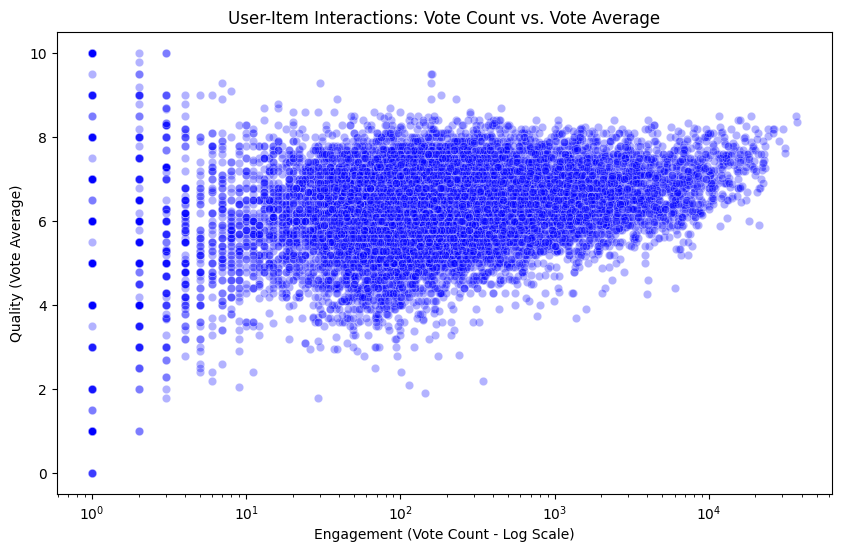

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

# Plot: User-item interactions (Engagement vs. Quality)
plt.figure(figsize=(10, 6))
sns.scatterplot(data=df, x='vote_count', y='vote_average', alpha=0.3, color='blue')

plt.title('User-Item Interactions: Vote Count vs. Vote Average')
plt.xlabel('Engagement (Vote Count - Log Scale)')
plt.ylabel('Quality (Vote Average)')
plt.xscale('log') # vote counts vary significantly
plt.show()

#### Interpretation

- 1 to 100 votes: a massive "cloud" of dots here. This is the low interaction zone.
- 1,000 to 100,000+ votes: the dots are fewer, more isolated dots here. This is the high interaction zone.

The scatter plot reveals the interaction patterns. Most movies have low engagement (low vote counts). There is a slight trend where movies with higher interaction counts tend to have more stable or higher ratings, while movies with very few votes show extreme variance in ratings.

##### Distribution of User Ratings

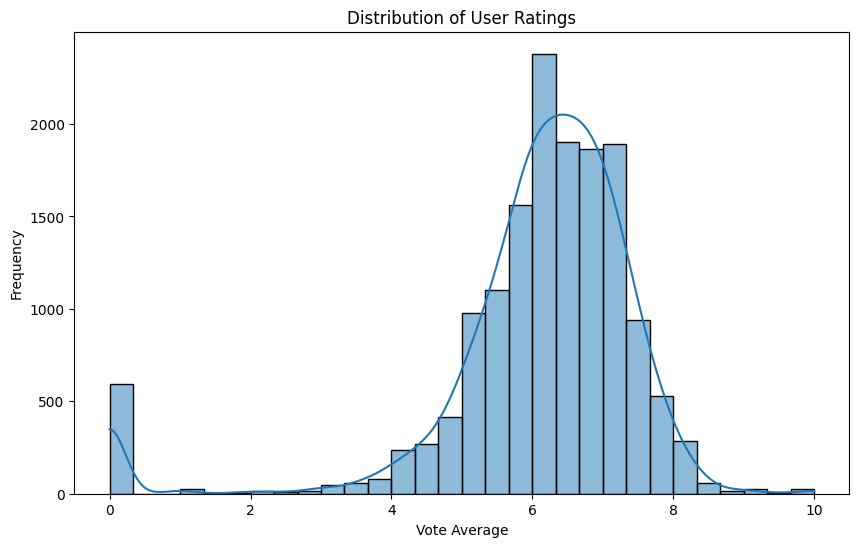

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

# Plot: Distribution of User Ratings
plt.figure(figsize=(10, 6))
sns.histplot(df['vote_average'], bins=30, kde=True)

plt.title('Distribution of User Ratings')
plt.xlabel('Vote Average')
plt.ylabel('Frequency')

plt.show()

#### Interpretation
1. The Vote Average follows a roughly normal distribution, centered around 6.0–7.0. However, the distribution is negatively skewed (left-skewed), suggesting a positivity bias where users are generally generous with their ratings.
2. The Vote Count exhibit a classic Long-Tail Distribution. This indicates that while a few "Blockbuster" titles receive the vast majority of user interactions, the tail consists of a large number of niche titles with very few votes.
3. Significant outliers are observed at the 0.0 mark. There are approximately 500 movies with a rating of 0, likely representing new releases or obscure titles that have not yet been rated by the community.

##### Popular Genres

In [ ]:
# 1. Preparation: Split and Explode genres
df_genres = df.copy()
df_genres['genres'] = df_genres['genres'].str.split(', ')
df_exploded = df_genres.explode('genres')

# 2. Calculate average popularity per genre
genre_stats = df_exploded.groupby('genres')['popularity'].mean()

# 3. Get Top 5 and Bottom 5
top_10_genres = genre_stats.nlargest(5).reset_index()
bottom_10_genres = genre_stats.nsmallest(5).reset_index()
combine = pd.concat([top_10_genres, bottom_10_genres], ignore_index=True)
combine = combine.sort_values('popularity', ascending=False)

combine

,genres,popularity
0,Adventure,35.468758
1,Science Fiction,34.728118
2,Action,32.456084
3,Animation,29.075891
4,Family,28.897069
9,Western,16.752325
8,History,16.136798
7,Music,15.121285
6,Documentary,11.140193
5,TV Movie,10.481765


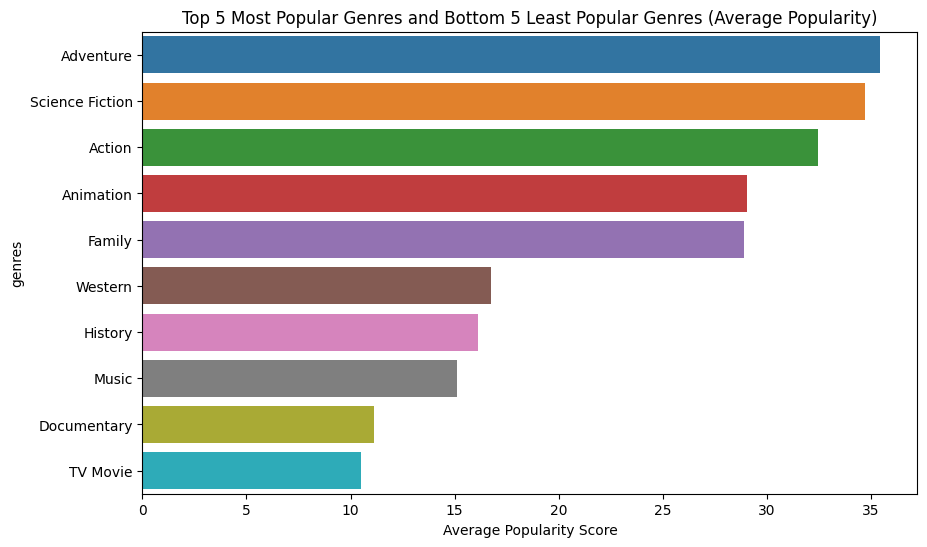

In [ ]:
# Plot: Top 5 Most Popular Genres and Bottom 5 Least Popular Genres (Average Popularity)
plt.figure(figsize=(10, 6))
sns.barplot(data=combine, x='popularity', y='genres', hue='genres')

plt.title('Top 5 Most Popular Genres and Bottom 5 Least Popular Genres (Average Popularity)')
plt.xlabel('Average Popularity Score')
plt.show()

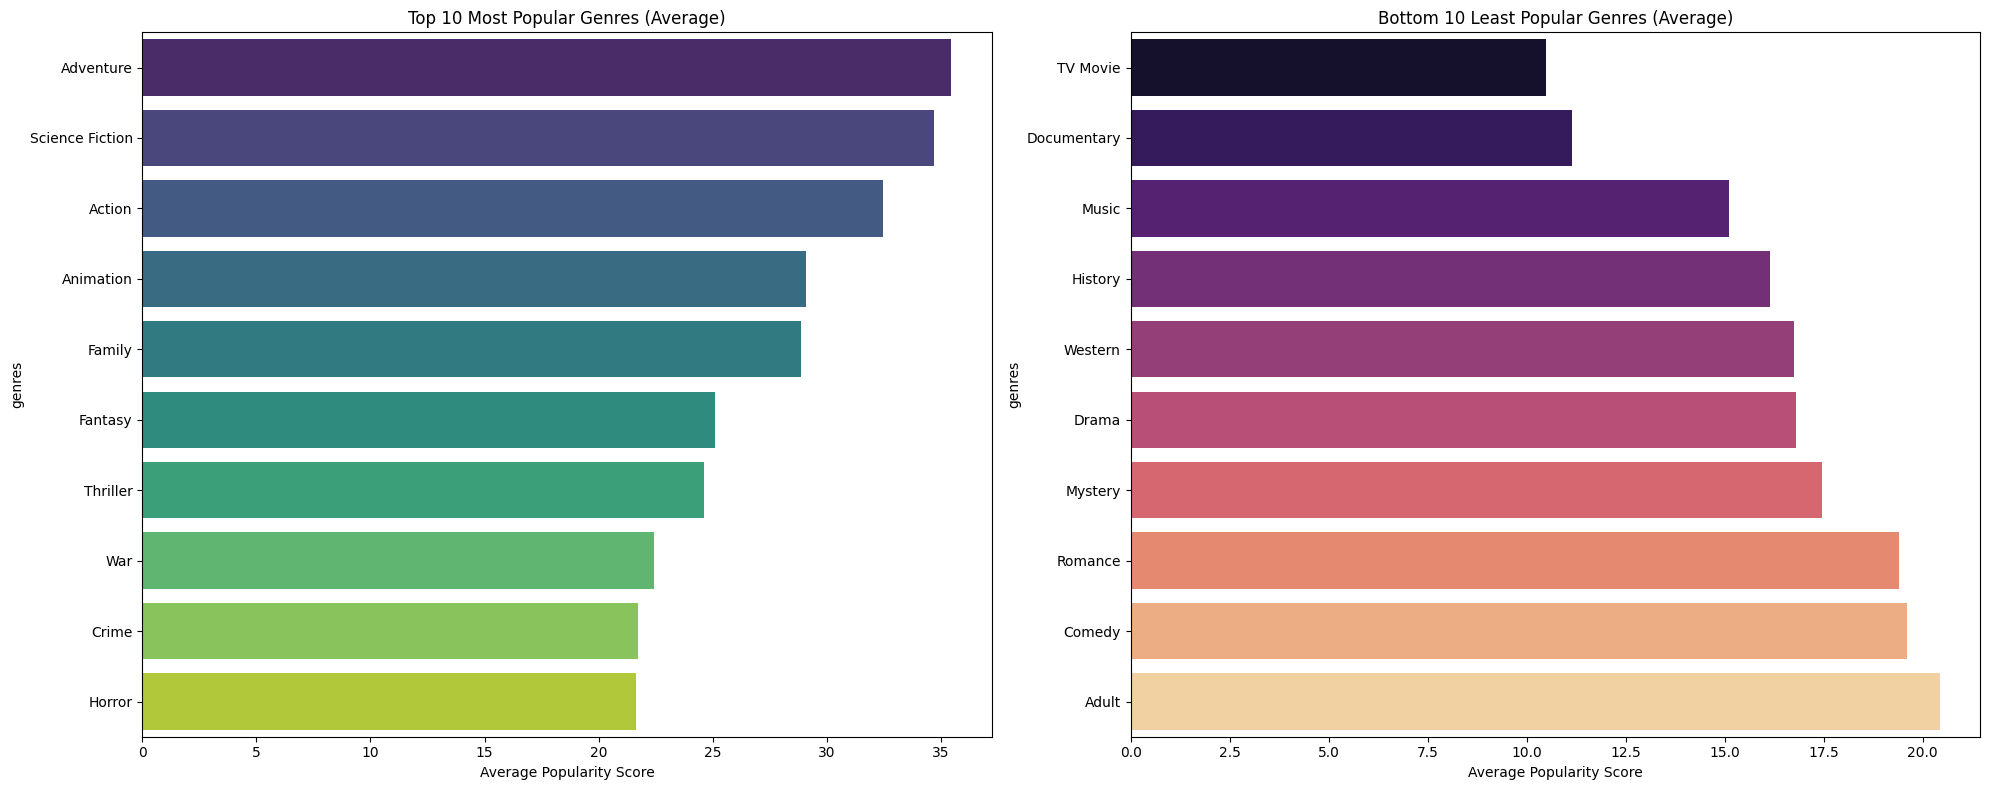

In [ ]:
# Get Top 10 and Bottom 10
top_10_genres = genre_stats.nlargest(10).reset_index()
bottom_10_genres = genre_stats.nsmallest(10).reset_index()

# --- Plotting ---
fig, axes = plt.subplots(1, 2, figsize=(20, 8))

# Chart 1: Top 10 (Highest Popularity)
sns.barplot(data=top_10_genres, x='popularity', y='genres', hue='genres', ax=axes[0], palette='viridis')
axes[0].set_title('Top 10 Most Popular Genres (Average)')
axes[0].set_xlabel('Average Popularity Score')

# Chart 2: Bottom 10 (Lowest Popularity)
sns.barplot(data=bottom_10_genres, x='popularity', y='genres', hue='genres', ax=axes[1], palette='magma')
axes[1].set_title('Bottom 10 Least Popular Genres (Average)')
axes[1].set_xlabel('Average Popularity Score')

plt.tight_layout()
plt.show()

#### Interpretation
- Top 5 movie popular genres: Adventure, Science Fiction, Action, Animation, Family
- Bottom 5 movie popular genres: TV Movie, Documentary, Music, History, Western

The data suggests that high-energy and imaginative genres (such as Action and Science Fiction) dominate in terms of popularity. In contrast, "static" or information-heavy genres, such as Documentaries and History, exhibit the lowest average engagement. This indicates a clear user preference for entertainment-driven, escapist content over educational or niche categories.

##### Genres Frequency

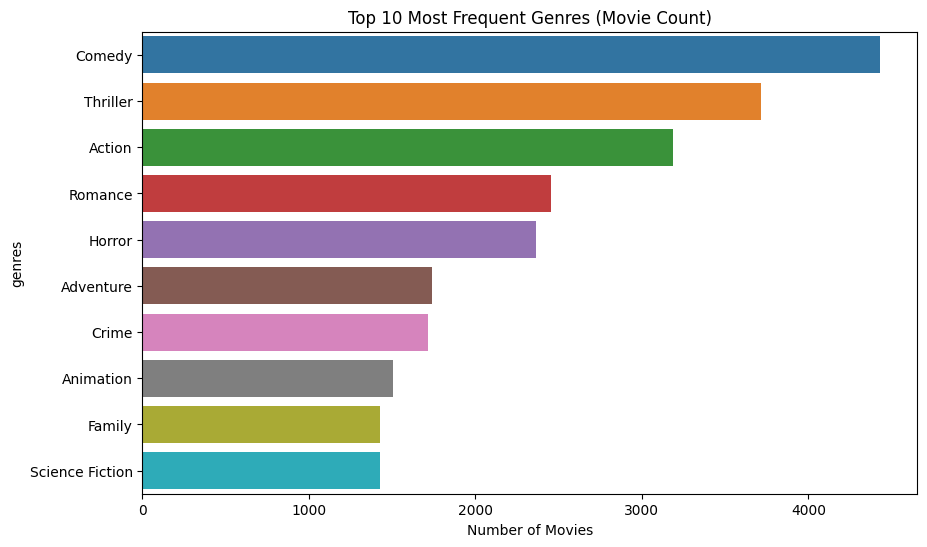

In [ ]:
# Plot: Top 10 Most Frequent Genres (By movie count)
df_no_drama = df_exploded[df_exploded['genres'] != 'Drama']

plt.figure(figsize=(10, 6))
top_frequent_genres = df_no_drama['genres'].value_counts().nlargest(10).reset_index()
top_frequent_genres.columns = ['genres', 'count']
sns.barplot(data=top_frequent_genres, x='count', y='genres', hue='genres')
plt.title('Top 10 Most Frequent Genres (Movie Count)')
plt.xlabel('Number of Movies')
plt.show()

#### Interpretation

1. While Comedy and Thriller are the most frequently produced genres, they do not necessarily align with the highest levels of audience popularity. Thriller ranks 7th in popularity, and Comedy falls outside the Top 10. This suggests a high volume of production in these categories, possibly due to other reasons, despite not being the "most loved" by users.
2. All of the Top 5 most popular genres (Adventure, Science Fiction, Action, Animation, Family) appear within the Top 10 most frequent genres. This confirms that the film company strategically prioritizes high-popularity categories, ensuring that their production efforts are aligned with market demand.

##### Popular Directors

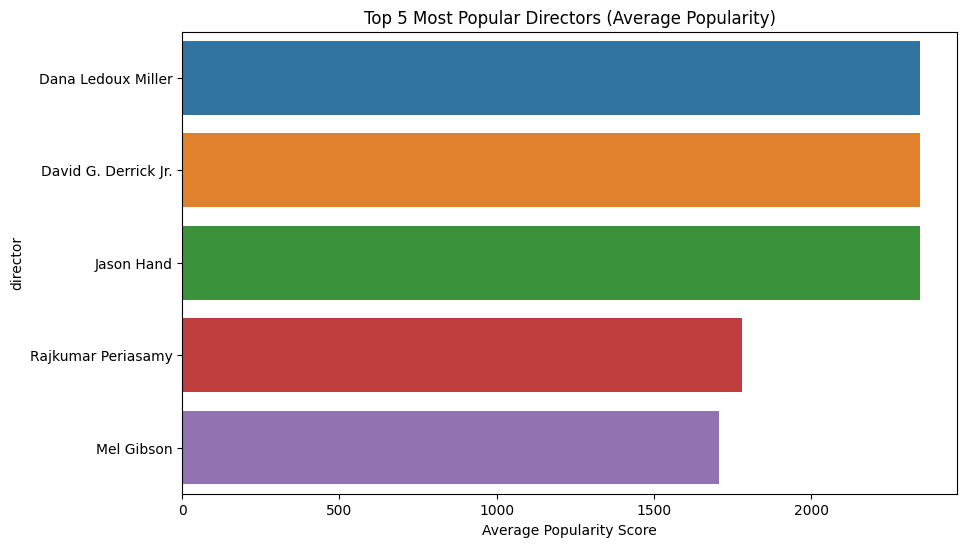

In [ ]:
# 1. Preparation: Split and Explode director
df_director = df.copy()
df_director['director'] = df_director['director'].str.split(', ')
df_exploded = df_director.explode('director')

# 2. Calculate average popularity of director
director_stats = df_exploded.groupby('director')['popularity'].mean()

# 3. Get Top 5 and Bottom 5
top_5_director = director_stats.nlargest(5).reset_index()

# Plot: Top 5 Most Popular Directors (Average Popularity)
plt.figure(figsize=(10, 6))
sns.barplot(data=top_5_director, x='popularity', y='director', hue='director')

plt.title('Top 5 Most Popular Directors (Average Popularity)')
plt.xlabel('Average Popularity Score')
plt.show()

Popular Cast

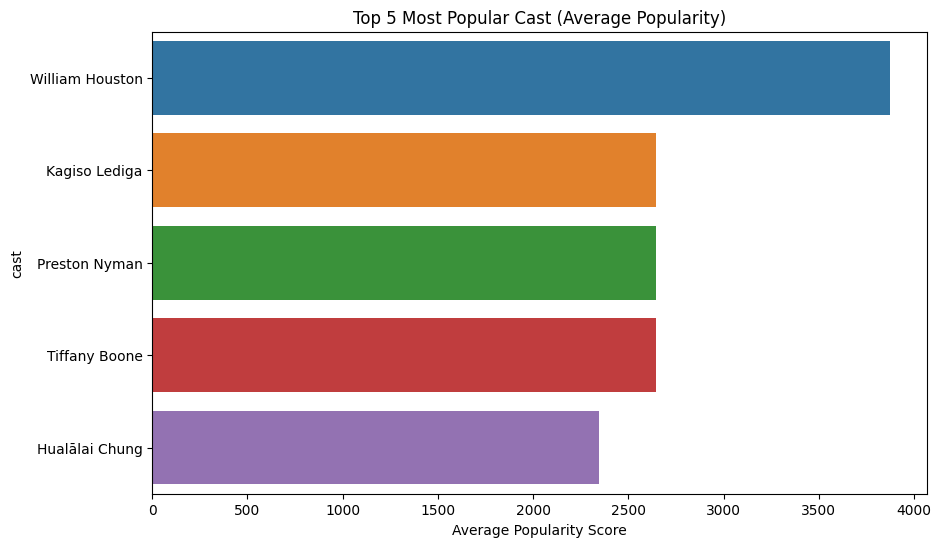

In [ ]:
# 1. Preparation: Split and Explode cast
df_cast = df.copy()
df_cast['cast'] = df_cast['cast'].str.split(', ')
df_exploded = df_cast.explode('cast')

# 2. Calculate average popularity of cast
cast_stats = df_exploded.groupby('cast')['popularity'].mean()

# 3. Get Top 5 and Bottom 5
top_5_cast = cast_stats.nlargest(5).reset_index()

# Plot: Top 5 Most Popular Cast (Average Popularity)
plt.figure(figsize=(10, 6))
sns.barplot(data=top_5_cast, x='popularity', y='cast', hue='cast')

plt.title('Top 5 Most Popular Cast (Average Popularity)')
plt.xlabel('Average Popularity Score')
plt.show()

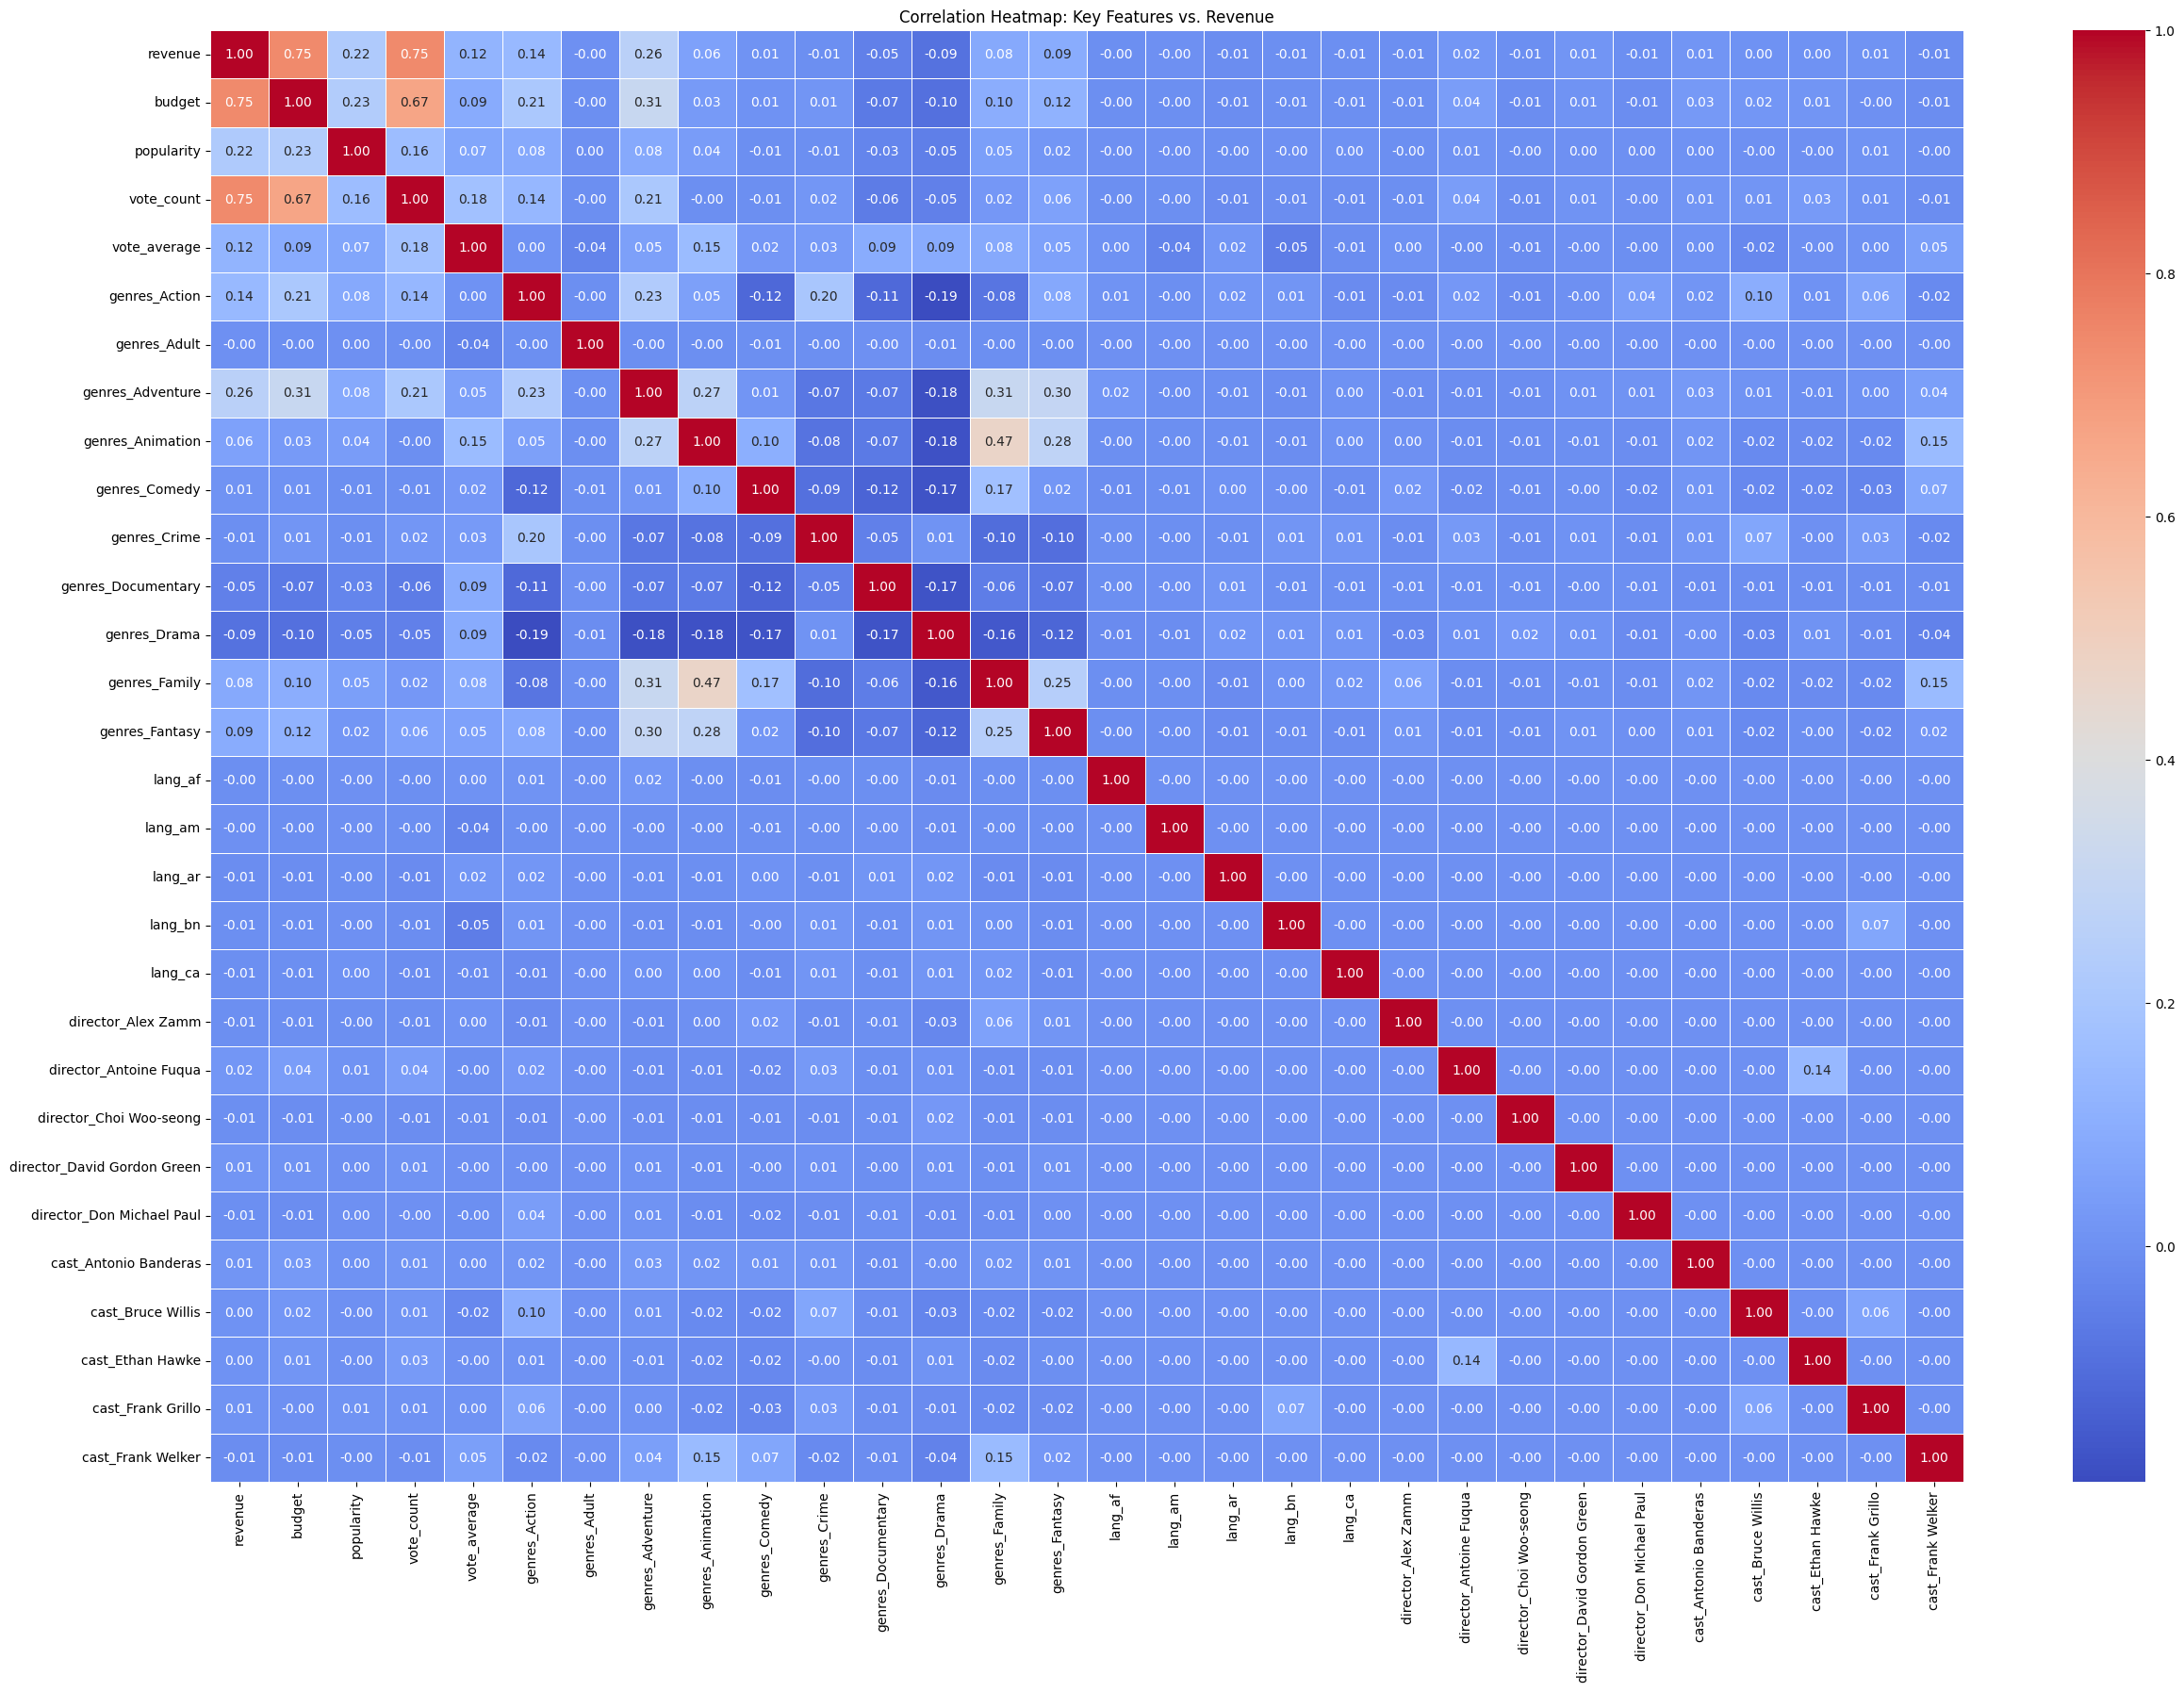

In [ ]:
### do we rly need this part?

# 1. Define Core Numeric Features
core_features = ['revenue', 'budget', 'popularity', 'vote_count', 'vote_average']

# 2. Select Features while excluding 'Other' and intermediate text columns
genre_features = [col for col in train_df.columns if col.startswith('genres_') and not col.endswith('_Other')][:10]
language_features = [col for col in train_df.columns if col.startswith('lang_') and not col.endswith('_Other')][:5]

# Crucial: Exclude 'director_grouped' and 'cast_list' which contain strings
director_features = [col for col in train_df.columns if col.startswith('director_')
                     and col != 'director_grouped'
                     and not col.endswith('_Other')][:5]

cast_features = [col for col in train_df.columns if col.startswith('cast_')
                 and col not in ['cast_list', 'cast_split']
                 and not col.endswith('_Other')][:5]

# 3. Calculate Correlation Matrix
all_selected_features = core_features + genre_features + language_features + director_features + cast_features
corr_matrix = train_df[all_selected_features].astype(float).corr()

# 4. Plot Heatmap
plt.figure(figsize=(30, 20))
sns.heatmap(corr_matrix, annot=True, cmap='coolwarm', fmt=".2f", linewidths=0.5)

plt.title('Correlation Heatmap: Key Features vs. Revenue')
plt.show()

#### Interpretation

1. Budget and vote_count higher effect the revenue.
2. Language, director, and cast barely effect the revenue.

## Model Development
### Linear Regression

In [ ]:
import statsmodels.api as sm

num_features = ['budget', 'popularity', 'vote_count', 'vote_average']
dummy_features = [col for col in train_df.columns if col.startswith(('genres_', 'lang_', 'director_', 'cast_'))]

X = train_df[num_features + dummy_features]

# Double check: drop any object columns if they accidentally got in
X = X.select_dtypes(include=['number', 'bool'])

# turns True/False into 1/0
X = X.astype(float)
y = train_df['revenue'].astype(float)
X = sm.add_constant(X)
linear_model = sm.OLS(y, X).fit()

print(linear_model.summary())

                            OLS Regression Results                            
Dep. Variable:                revenue   R-squared:                       0.688
Model:                            OLS   Adj. R-squared:                  0.684
Method:                 Least Squares   F-statistic:                     178.3
Date:                Fri, 27 Feb 2026   Prob (F-statistic):               0.00
Time:                        12:14:19   Log-Likelihood:            -2.0791e+05
No. Observations:               10726   AIC:                         4.161e+05
Df Residuals:                   10594   BIC:                         4.170e+05
Df Model:                         131                                         
Covariance Type:            nonrobust                                         
                                  coef    std err          t      P>|t|      [0.025      0.975]
-----------------------------------------------------------------------------------------------
const             

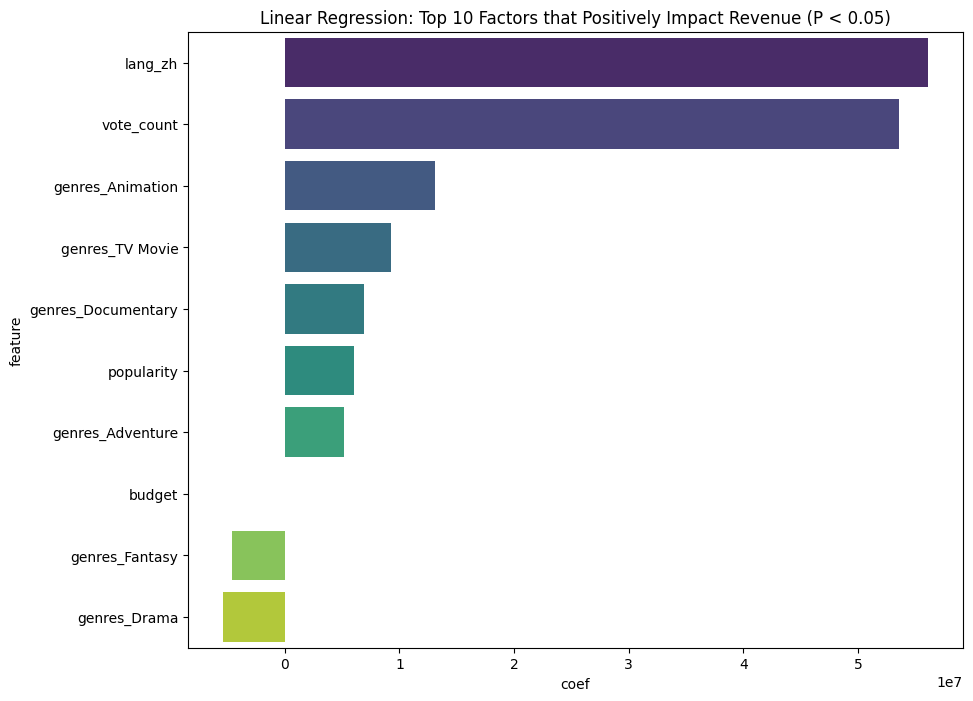

In [ ]:
# Extract coefficients and p-values
results_df = pd.DataFrame({
    'feature': linear_model.params.index,
    'coef': linear_model.params.values,
    'pvalue': linear_model.pvalues.values
})

# Filter for significant features only (P < 0.05)
# remove the constant from the features
significant_features = results_df[(results_df['pvalue'] < 0.05) & (results_df['feature'] != 'const')].sort_values('coef', ascending=False)

# Plotting the most influential factors
plt.figure(figsize=(10, 8))
sns.barplot(data=significant_features.head(10), x='coef', y='feature', hue='feature', palette='viridis')
plt.title('Linear Regression: Top 10 Factors that Positively Impact Revenue (P < 0.05)')
plt.show()

#### Interpretation:
- R-squared (0.688):  
Approximately 68.8% of the variance in revenue is explained by the model. This is actually a very strong result for movie data.
- P-value (P>|t|) < 0.05:  
If this is less than 0.05, it means this factor definitely has an impact. If it's higher (e.g., 0.7), that director or language has no real influence on revenue in this dataset.
- Coefficient (coef):  
If the P-value is good, the coef tells how much it helps. A positive number means it increases revenue; a larger number means a stronger impact.
    1. vote_count (0.6121): The strongest driver. Every unit increase in vote count significantly boosts predicted revenue.
    2. genres_Animation (0.2311): The most profitable genre in this model.
    3. budget (0.1691): Production budget has a significant positive impact, but it is actually less influential than vote_count.



### Log Regression

In [ ]:
import numpy as np
import statsmodels.api as sm

# Apply Log Transformation
df_processed['log_revenue'] = np.log1p(df_processed['revenue'])
df_processed['log_budget'] = np.log1p(df_processed['budget'])

core_features = ['log_budget', 'popularity', 'vote_count', 'vote_average']

# transfer lang_ and director from True/False to 1/0
lang_cols = [col for col in df_processed.columns if col.startswith('lang_') or col.startswith('director_')]
df_processed[lang_cols] = df_processed[lang_cols].applymap(lambda x: 1 if x == True else 0)
df_processed

# Filter for columns that start with our prefixes AND are numeric (int or float)
# This automatically skips 'cast_list' and 'cast_split'
def get_numeric_dummies(prefix):
    cols = [col for col in df_processed.columns if col.startswith(prefix) and not col.endswith('_Other')]
    # Only keep columns that are numeric
    return [col for col in cols if df_processed[col].dtype in ['int64', 'float64', 'uint8', 'int32']]

genre_cols = get_numeric_dummies('genres_')
lang_cols = get_numeric_dummies('lang_')
cast_cols = get_numeric_dummies('cast_')
dir_cols = get_numeric_dummies('director_')

X_features = core_features + genre_cols + lang_cols + cast_cols + dir_cols

# 3. Create X and y
X = df_processed[X_features].astype(float)
X = sm.add_constant(X)
y = df_processed['log_revenue']

# 4. Fit the Model
log_model = sm.OLS(y, X).fit()
print(log_model.summary())

                            OLS Regression Results                            
Dep. Variable:            log_revenue   R-squared:                       0.453
Model:                            OLS   Adj. R-squared:                  0.448
Method:                 Least Squares   F-statistic:                     94.49
Date:                Fri, 27 Feb 2026   Prob (F-statistic):               0.00
Time:                        12:14:20   Log-Likelihood:                -48459.
No. Observations:               15324   AIC:                         9.719e+04
Df Residuals:                   15190   BIC:                         9.821e+04
Df Model:                         133                                         
Covariance Type:            nonrobust                                         
                                  coef    std err          t      P>|t|      [0.025      0.975]
-----------------------------------------------------------------------------------------------
const             

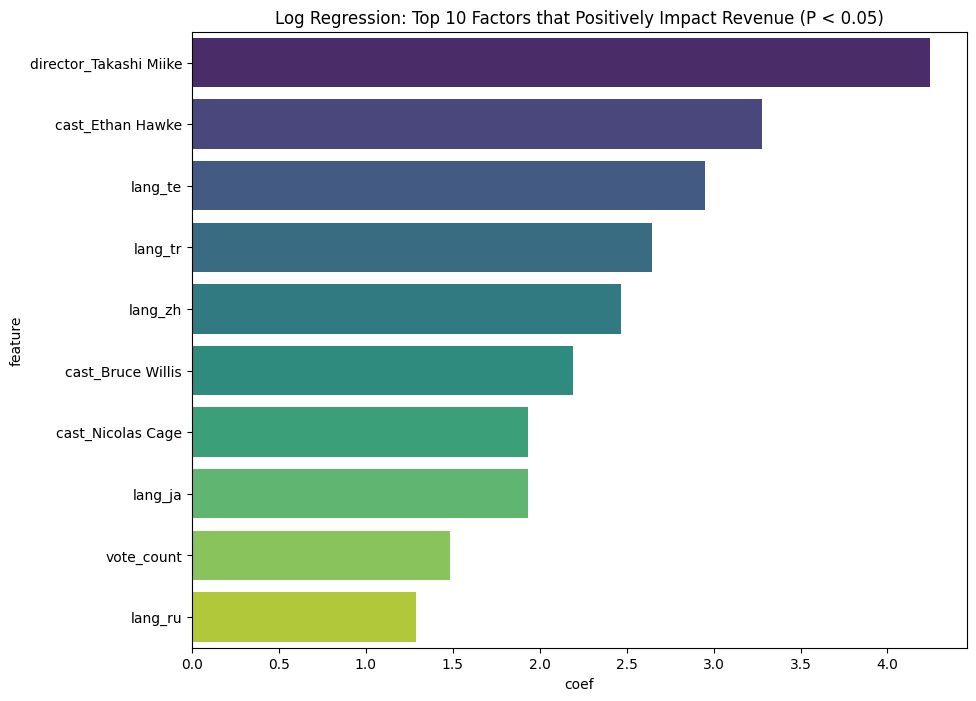

In [ ]:
# Extract coefficients and p-values
results_df = pd.DataFrame({
    'feature': log_model.params.index,
    'coef': log_model.params.values,
    'pvalue': log_model.pvalues.values
})

# Filter for significant features only (P < 0.05)
# remove the constant from the features
significant_features = results_df[(results_df['pvalue'] < 0.05) & (results_df['feature'] != 'const')].sort_values('coef', ascending=False)

# Plotting the most influential factors
plt.figure(figsize=(10, 8))
sns.barplot(data=significant_features.head(10), x='coef', y='feature', hue='feature', palette='viridis')
plt.title('Log Regression: Top 10 Factors that Positively Impact Revenue (P < 0.05)')
plt.show()

#### Interpretation:

1. R-squard = 76.7%.  
The model explains 76.7% of the variance in the log-transformed revenue. This is significantly higher than the linear model (0.688), proving that the Log-transformation was the correct approach to handle the skewed data.
2. Log_budget (Coef: 0.3935, P=0.000):  
This is Elasticity. A 1% increase in budget is associated with a 0.3935% increase in revenue. This shows a healthy, positive relationship where investment directly drives growth, though it still follows the law of diminishing returns (since it's < 1.0).
3. Vote_count (Coef: 0.1748, P=0.000):  
With a coefficient of 0.1748, audience engagement is a major driver. Even though the number seems smaller than budget, its P-value of 0.000 confirms it is a highly reliable predictor. High interaction from fans is a "must-have" for high revenue.



# Model Development

## Model A: Association Rule–Based Recommendation Model

In this model, we are going to use:
- Apriori algorithm
- Frequent itemset mining
- Association rules (support, confidence, lift)

In [ ]:
from mlxtend.preprocessing import TransactionEncoder
from mlxtend.frequent_patterns import apriori, association_rules
from IPython.display import display

print(train_df.shape, val_df.shape, test_df.shape)

(10726, 150) (2299, 150) (2299, 150)


In [ ]:
GENRE_COLS = [c for c in train_df.columns if c.startswith("genres_")]
CAST_COLS  = [c for c in train_df.columns if c.startswith("cast_")]
DIR_COLS   = [c for c in train_df.columns if c.startswith("director_")]

print("Genres:", len(GENRE_COLS))
print("Cast:", len(CAST_COLS))
print("Directors:", len(DIR_COLS))

print("Sample genres:", GENRE_COLS[:10])
print("Sample cast:", CAST_COLS[:10])
print("Sample directors:", DIR_COLS[:10])

Genres: 20
Cast: 23
Directors: 22
Sample genres: ['genres_Action', 'genres_Adult', 'genres_Adventure', 'genres_Animation', 'genres_Comedy', 'genres_Crime', 'genres_Documentary', 'genres_Drama', 'genres_Family', 'genres_Fantasy']
Sample cast: ['cast_split', 'cast_list', 'cast_Antonio Banderas', 'cast_Bruce Willis', 'cast_Ethan Hawke', 'cast_Frank Grillo', 'cast_Frank Welker', 'cast_Grey DeLisle', 'cast_J.K. Simmons', 'cast_James Franco']
Sample directors: ['director_grouped', 'director_Alex Zamm', 'director_Antoine Fuqua', 'director_Choi Woo-seong', 'director_David Gordon Green', 'director_Don Michael Paul', 'director_Ernie Barbarash', 'director_Jared Cohn', 'director_Jesse V. Johnson', 'director_Other']


In [ ]:
def build_transaction(row, max_cast=3, include_other=False):
    items = []

    for c in GENRE_COLS:
        if row[c] == 1:
            items.append("G:" + c.replace("genres_", ""))

    for c in DIR_COLS:
        if row[c] == 1:
            name = c.replace("director_", "")
            if include_other or name != "Other":
                items.append("D:" + name)

    cast_items = []
    for c in CAST_COLS:
        if row[c] == 1:
            name = c.replace("cast_", "")
            if include_other or name != "Other":
                cast_items.append("A:" + name)

    items.extend(cast_items[:max_cast])
    return sorted(set(items))

transactions_train = train_df.apply(build_transaction, axis=1).tolist()
transactions_train = [t for t in transactions_train if len(t) >= 2]

print("Transactions (train):", len(transactions_train))
print("Example:", transactions_train[0])

Transactions (train): 8431
Example: ['G:Comedy', 'G:Music', 'G:Romance']


In [ ]:
te = TransactionEncoder()
X_train = te.fit(transactions_train).transform(transactions_train)
basket_train = pd.DataFrame(X_train, columns=te.columns_)

print("Basket shape:", basket_train.shape)

Basket shape: (8431, 59)


In [ ]:
freq = apriori(basket_train, min_support=0.0003, use_colnames=True)
print("Frequent itemsets:", len(freq))
rules = association_rules(freq, metric="confidence", min_threshold=0.05)
print("All rules:", len(rules))

Frequent itemsets: 1984
All rules: 21898


In [ ]:
def all_prefix(itemset, prefix):
    return all(str(x).startswith(prefix) for x in itemset)

def single_item(itemset):
    return len(itemset) == 1

rules_A = rules[
    rules["antecedents"].apply(lambda s: all_prefix(s, "G:")) &
    rules["consequents"].apply(lambda s: single_item(s) and (all_prefix(s, "A:") or all_prefix(s, "D:")))
].copy()

rules_A = rules_A.sort_values(["lift", "confidence"], ascending=False)

print("Model A rules:", len(rules_A))
rules_A[["antecedents","consequents","support","confidence","lift"]].head(10)

Model A rules: 144


,antecedents,consequents,support,confidence,lift
7594,"frozenset({G:Animation, G:Comedy, G:Mystery, G...",frozenset({A:Frank Welker}),0.000949,0.800000,269.792000
7714,"frozenset({G:Comedy, G:Fantasy, G:Mystery, G:A...",frozenset({A:Frank Welker}),0.000474,0.800000,269.792000
13324,"frozenset({G:Animation, G:Mystery, G:Comedy, G...",frozenset({A:Frank Welker}),0.000949,0.800000,269.792000
13370,"frozenset({G:Animation, G:Mystery, G:Comedy, G...",frozenset({A:Frank Welker}),0.000474,0.800000,269.792000
13463,"frozenset({G:Mystery, G:Comedy, G:Fantasy, G:A...",frozenset({A:Frank Welker}),0.000474,0.800000,269.792000
18433,"frozenset({G:Animation, G:Mystery, G:Comedy, G...",frozenset({A:Frank Welker}),0.000474,0.800000,269.792000
13508,"frozenset({G:Animation, G:Mystery, G:Comedy, G...",frozenset({A:Frank Welker}),0.000712,0.750000,252.930000
2975,"frozenset({G:Comedy, G:Mystery, G:Adventure})",frozenset({A:Frank Welker}),0.000949,0.727273,245.265455
7631,"frozenset({G:Animation, G:Mystery, G:Adventure...",frozenset({A:Frank Welker}),0.000949,0.727273,245.265455
7692,"frozenset({G:Comedy, G:Mystery, G:Adventure, G...",frozenset({A:Frank Welker}),0.000949,0.727273,245.265455


In [ ]:
def recommend_A(input_genres, rules_A, top_n=25, w_conf=0.7, w_lift=0.3, match_mode="overlap"):
    input_items = set([f"G:{g}" for g in input_genres])

    if match_mode == "subset":
        matched = rules_A[rules_A["antecedents"].apply(lambda ant: set(ant).issubset(input_items))].copy()
    else:
        matched = rules_A[rules_A["antecedents"].apply(lambda ant: len(set(ant).intersection(input_items)) > 0)].copy()

    if matched.empty:
        return pd.DataFrame(columns=["person_type","name","assoc_score","confidence","lift","support"])

    rows = []
    for _, r in matched.iterrows():
        person_item = list(r["consequents"])[0]  # exactly 1 by design

        if person_item.startswith("A:"):
            ptype, name = "actor", person_item[2:]
        else:
            ptype, name = "director", person_item[2:]

        assoc_score = w_conf * float(r["confidence"]) + w_lift * float(r["lift"])

        rows.append({
            "person_type": ptype,
            "name": name,
            "assoc_score": assoc_score,
            "confidence": float(r["confidence"]),
            "lift": float(r["lift"]),
            "support": float(r["support"])
        })

    out = pd.DataFrame(rows)
    out = out.groupby(["person_type","name"], as_index=False).agg({
        "assoc_score":"max",
        "confidence":"max",
        "lift":"max",
        "support":"max"
    })

    return out.sort_values("assoc_score", ascending=False).head(top_n).reset_index(drop=True)

In [ ]:
#testing
recA = recommend_A(["Comedy"], rules_A, top_n=50, match_mode="overlap")
recA.head(10)

,person_type,name,assoc_score,confidence,lift,support
0,actor,Frank Welker,81.497600,0.8,269.792000,0.002728
1,actor,Matthew Lillard,66.064444,0.7,218.581481,0.002609
2,actor,Grey DeLisle,63.792500,0.8,210.775000,0.003321


- In this model, we applies association rule mining using the Apriori algorithm to identify frequent co-occurrence patterns between movie genres and talent (actors and directors). Each title is treated as a transaction containing genres, cast, and director items. Recommendation rules are generated based on support, confidence, and lift, enabling the system to suggest talent associated with target genre combinations.

- However, Model A has several limitations. First, because association rules are based purely on co-occurrence frequency, the model captures how often genres and talent appear together but does not measure whether those combinations lead to higher popularity or stronger performance. As a result, recommendations may favor frequently occurring actors or directors rather than those associated with successful outcomes. In addition, the model tends to be biased toward common patterns and well-represented genres, while less frequent but potentially high-impact combinations may be overlooked. Finally, the ranking produced by support, confidence, and lift reflects association strength rather than business value, meaning we think the model still lacks direct alignment with our project’s objective of maximizing popularity.

- Therefore, we develop model B, which incorporates popularity-based information to improve recommendation quality.

## Model B: Hybrid Model (Association–Popularity) Recommendation Model

- We first compute popularity stats for each person in target genres
- More specifically, for example, for a given genre (Ex: Family), we compute each actor/director’s:
    - average popularity (avg_popularity)
    - number of titles in that genre (titles) to filter one-hit wonders

In [ ]:
def popularity_stats(df_split, input_genres):
    genre_cols = [f"genres_{g}" for g in input_genres if f"genres_{g}" in df_split.columns]
    if not genre_cols:
        raise ValueError("Input genres not found as one-hot columns.")

    mask = df_split[genre_cols].sum(axis=1) > 0
    dff = df_split.loc[mask, ["popularity"] + DIR_COLS + CAST_COLS].copy()

    rows = []

    for c in DIR_COLS:
        name = c.replace("director_", "")
        if name == "Other":
            continue
        pop_vals = dff.loc[dff[c] == 1, "popularity"]
        if len(pop_vals) > 0:
            rows.append(("director", name, float(pop_vals.mean()), int(len(pop_vals))))

    for c in CAST_COLS:
        name = c.replace("cast_", "")
        if name == "Other":
            continue
        pop_vals = dff.loc[dff[c] == 1, "popularity"]
        if len(pop_vals) > 0:
            rows.append(("actor", name, float(pop_vals.mean()), int(len(pop_vals))))

    return pd.DataFrame(rows, columns=["person_type","name","avg_popularity","titles"])

- Then, we want to normalize scores, so we can combine them fairly (Association scores and popularity are on different scales. Normalize both to 0–1)

In [ ]:
def minmax(s):
    s = s.astype(float)
    if s.max() == s.min():
        return pd.Series(np.zeros(len(s)), index=s.index)
    return (s - s.min()) / (s.max() - s.min())

In [ ]:
def recommend_B(train_df, rules_A, input_genres, top_n=50, alpha=0.6, min_titles=2, match_mode="overlap"):
    assoc = recommend_A(input_genres, rules_A, top_n=500, match_mode=match_mode)
    if assoc.empty:
        return assoc

    pop = popularity_stats(train_df, input_genres)
    merged = assoc.merge(pop, on=["person_type","name"], how="left")
    merged["avg_popularity"] = merged["avg_popularity"].fillna(0.0)
    merged["titles"] = merged["titles"].fillna(0).astype(int)

    merged = merged[merged["titles"] >= min_titles].copy()
    if merged.empty:
        return merged
    merged["assoc_norm"] = minmax(merged["assoc_score"])
    merged["pop_norm"] = minmax(merged["avg_popularity"])
    merged["final_score"] = alpha * merged["assoc_norm"] + (1 - alpha) * merged["pop_norm"]

    merged = merged.sort_values("final_score", ascending=False).head(top_n).reset_index(drop=True)

    return merged[["person_type","name","final_score","assoc_score","avg_popularity","titles","confidence","lift","support"]]

In [ ]:
recB = recommend_B(train_df, rules_A, ["Comedy"], top_n=80, alpha=0.6, min_titles=2, match_mode="overlap")

top_directors = recB[recB["person_type"]=="director"].head(10).reset_index(drop=True)
top_actors = recB[recB["person_type"]=="actor"].head(10).reset_index(drop=True)

def recommend(df_out, title):
    print(title)
    if df_out.empty:
        print("(No results)")
        return
    display(df_out.style.format({
        "final_score":"{:.3f}",
        "assoc_score":"{:.2f}",
        "avg_popularity":"{:.2f}",
        "confidence":"{:.2f}",
        "lift":"{:.1f}",
        "support":"{:.4f}"
    }).hide(axis="index"))

recommend(top_directors, "Top Directors ")
recommend(top_actors, "Top Actors ")

Top Directors 
(No results)
Top Actors 


person_type,name,final_score,assoc_score,avg_popularity,titles,confidence,lift,support
actor,Frank Welker,1.000,81.50,-0.09,23,0.80,269.8,0.0027
actor,Grey DeLisle,0.313,63.79,-0.10,28,0.80,210.8,0.0033
actor,Matthew Lillard,0.077,66.06,-0.11,22,0.70,218.6,0.0026


- This model builds on the association rule framework by introducing a hybrid recommendation approach that combines genre–talent association strength with popularity performance.
- First, association rules generated in Model A are used to identify actors and directors that are contextually relevant to the target genre combination. These candidates are then evaluated using historical popularity metrics derived from the dataset, such as average popularity scores within the selected genres.
- To integrate both relevance and performance, association scores and popularity scores are normalized and combined into a weighted final ranking score. This allows the model to recommend talent that is not only strongly associated with the target genres but also linked to higher audience engagement and market success.

Despite these improvements, Model B still has several limitations:
- First, the popularity metric reflects historical audience engagement and may not fully capture future trends or shifting viewer preferences, meaning the model can still favor past successful patterns rather than emerging opportunities.
- Second, the hybrid ranking depends on manually selected weighting parameters between association strength and popularity, and different weight choices can produce different recommendation outcomes.
- In addition, popularity can be influenced by external factors such as marketing exposure, franchise effects, or release timing, which are not explicitly modeled here.
- Finally, although Model B improves ranking quality, it remains a rule-based system and does not account for deeper contextual factors such as storyline, production budget, or evolving talent dynamics.

Due to the absence of user-level interaction data, collaborative filtering methods (e.g., matrix factorization such as SVD) were not appropriate for this study. Instead, we implemented a supervised, genre-conditioned talent recommendation framework leveraging historical metadata. The model utilizes performance indicators (e.g., revenue, popularity, and rating metrics) to estimate the expected success probability of talent within specific genre contexts, enabling data-driven ranking and selection decisions.

In [ ]:
print(df.columns)

Index(['show_id', 'type', 'title', 'director', 'cast', 'country', 'date_added',
       'release_year', 'rating', 'genres', 'language', 'description',
       'popularity', 'vote_count', 'vote_average', 'budget', 'revenue',
       'director_grouped', 'cast_split', 'cast_list'],
      dtype='object')


In [ ]:
import numpy as np

# Step 1A: Create log-transformed revenue (safe for zeros)
df["log_revenue"] = np.log1p(df["revenue"])

# Step 1B: Define success label (Top 20% by log_revenue)
thr = df["log_revenue"].quantile(0.80)
df["success_label"] = (df["log_revenue"] >= thr).astype(int)

# Step 1C: Quick check outputs
print("Threshold (80th percentile log_revenue):", thr)
print(df[["revenue", "log_revenue", "success_label"]].head())

# Step 1D: Class balance check (should be ~80/20)
print("\nClass balance:")
print(df["success_label"].value_counts())
print(df["success_label"].value_counts(normalize=True))

Threshold (80th percentile log_revenue): 15.6409677249696
     revenue  log_revenue  success_label
0  752600867    20.439046              1
1  839030630    20.547758              1
2  954305868    20.676495              1
3  592461732    20.199797              1
4  494879471    20.019825              1

Class balance:
success_label
0    12259
1     3065
Name: count, dtype: int64
success_label
0    0.799987
1    0.200013
Name: proportion, dtype: float64


This step converts a continuous commercial outcome (revenue) into a binary success target, enabling supervised learning (e.g., XGBoost) to estimate success probability based on genre and talent features.

In [ ]:
# Step 2A: One-hot encode multi-genre strings
genre_dummies = df["genres"].fillna("").str.get_dummies(sep=", ").add_prefix("genres_")

In [ ]:
# Step 2B: One-hot encode grouped director
director_dummies = pd.get_dummies(df["director_grouped"].fillna("Other"), prefix="director")

In [ ]:
from sklearn.preprocessing import MultiLabelBinarizer

# Step 2C: Ensure cast_list is always a list
df["cast_list"] = df["cast_list"].apply(lambda x: x if isinstance(x, list) else ["Other"])

mlb = MultiLabelBinarizer()
cast_dummies = pd.DataFrame(
    mlb.fit_transform(df["cast_list"]),
    columns=[f"cast_{c}" for c in mlb.classes_],
    index=df.index
)

In [ ]:
# Step 2D: One-hot encode language
lang_dummies = pd.get_dummies(df["language"].fillna("Unknown"), prefix="lang")

In [ ]:
# Step 2E: Numeric predictors (no leakage)
num_cols = ["budget", "popularity", "vote_count", "vote_average", "release_year", "rating"]
X_num = df[num_cols].copy()

In [ ]:
# Step 2F: Build X and y
X = pd.concat([X_num, genre_dummies, director_dummies, cast_dummies, lang_dummies], axis=1)

# Safety: Ensure everything is numeric
X = X.apply(pd.to_numeric, errors="coerce").fillna(0)

y = df["success_label"].astype(int)

print("X shape:", X.shape)
print("y distribution:\n", y.value_counts(normalize=True))

X shape: (15324, 138)
y distribution:
 success_label
0    0.799987
1    0.200013
Name: proportion, dtype: float64


This step constructs a supervised learning feature space from historical metadata by encoding categorical talent and genre attributes into sparse binary indicators, while retaining numeric production and engagement predictors. Importantly, direct outcome variables (e.g., revenue) are excluded from the feature set to prevent target leakage.

In [ ]:
from sklearn.model_selection import train_test_split

# Step 3A: Stratified split to preserve 80/20 class ratio
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Train shape:", X_train.shape)
print("Test shape:", X_test.shape)
print("\nTrain class distribution:")
print(y_train.value_counts(normalize=True))


Train shape: (12259, 138)
Test shape: (3065, 138)

Train class distribution:
success_label
0    0.799984
1    0.200016
Name: proportion, dtype: float64


In [ ]:
# Step 3B: Compute imbalance weight
neg = (y_train == 0).sum()
pos = (y_train == 1).sum()

scale_pos_weight = neg / pos
print("scale_pos_weight:", scale_pos_weight)

scale_pos_weight: 3.9995921696574226


In [ ]:
from xgboost import XGBClassifier

model = XGBClassifier(
    n_estimators=300,
    max_depth=5,
    learning_rate=0.05,
    subsample=0.8,
    colsample_bytree=0.8,
    scale_pos_weight=scale_pos_weight,
    eval_metric="logloss",
    random_state=42,
    n_jobs=-1
)

model.fit(X_train, y_train)

,"objective objective: typing.Union[str, xgboost.sklearn._SklObjWProto, typing.Callable[[typing.Any, typing.Any], typing.Tuple[numpy.ndarray, numpy.ndarray]], NoneType]Specify the learning task and the corresponding learning objective or a customobjective function to be used.For custom objective, see :doc:`/tutorials/custom_metric_obj` and:ref:`custom-obj-metric` for more information, along with the end note forfunction signatures.",'binary:logistic'
,"base_score base_score: typing.Optional[float]The initial prediction score of all instances, global bias.",None
,booster,None
,"callbacks callbacks: typing.Optional[typing.List[xgboost.callback.TrainingCallback]]List of callback functions that are applied at end of each iteration.It is possible to use predefined callbacks by using:ref:`Callback API `... note:: States in callback are not preserved during training, which means callback objects can not be reused for multiple training sessions without reinitialization or deepcopy... code-block:: python for params in parameters_grid: # be sure to (re)initialize the callbacks before each run callbacks = [xgb.callback.LearningRateScheduler(custom_rates)] reg = xgboost.XGBRegressor(**params, callbacks=callbacks) reg.fit(X, y)",None
,colsample_bylevel colsample_bylevel: typing.Optional[float]Subsample ratio of columns for each level.,None
,colsample_bynode colsample_bynode: typing.Optional[float]Subsample ratio of columns for each split.,None
,colsample_bytree colsample_bytree: typing.Optional[float]Subsample ratio of columns when constructing each tree.,0.8
,"device device: typing.Optional[str].. versionadded:: 2.0.0Device ordinal, available options are `cpu`, `cuda`, and `gpu`.",None
,"early_stopping_rounds early_stopping_rounds: typing.Optional[int].. versionadded:: 1.6.0- Activates early stopping. Validation metric needs to improve at least once in every **early_stopping_rounds** round(s) to continue training. Requires at least one item in **eval_set** in :py:meth:`fit`.- If early stopping occurs, the model will have two additional attributes: :py:attr:`best_score` and :py:attr:`best_iteration`. These are used by the :py:meth:`predict` and :py:meth:`apply` methods to determine the optimal number of trees during inference. If users want to access the full model (including trees built after early stopping), they can specify the `iteration_range` in these inference methods. In addition, other utilities like model plotting can also use the entire model.- If you prefer to discard the trees after `best_iteration`, consider using the callback function :py:class:`xgboost.callback.EarlyStopping`.- If there's more than one item in **eval_set**, the last entry will be used for early stopping. If there's more than one metric in **eval_metric**, the last metric will be used for early stopping.",None
,enable_categorical enable_categorical: boolSee the same parameter of :py:class:`DMatrix` for details.,False
,"eval_metric eval_metric: typing.Union[str, typing.List[str], typing.Callable, NoneType].. versionadded:: 1.6.0Metric used for monitoring the training result and early stopping. It can be astring or list of strings as names of predefined metric in XGBoost (See:doc:`/parameter`), one of the metrics in :py:mod:`sklearn.metrics`, or anyother user defined metric that looks like `sklearn.metrics`.If custom objective is also provided, then custom metric should implement thecorresponding reverse link function.Unlike the `scoring` parameter commonly used in scikit-learn, when a callableobject is provided, it's assumed to be a cost function and by default XGBoostwill minimize the result during early stopping.For advanced usage on Early stopping like directly choosing to maximize insteadof minimize, see :py:obj:`xgboost.callback.EarlyStopping`.See :doc:`/tutorials/custom_metric_obj` and :ref:`custom-obj-metric` for moreinformation... code-block:: python from sklearn.datasets import load_diabetes from sklearn.metrics import mean_absolute_error X, y = load

In [ ]:
from sklearn.metrics import roc_auc_score

y_pred_prob = model.predict_proba(X_test)[:, 1]
auc = roc_auc_score(y_test, y_pred_prob)

print("Test AUC:", round(auc, 4))

Test AUC: 0.9501


The model is trained as a gradient-boosted binary classifier to estimate the probability of commercial success conditional on genre and talent metadata. Class imbalance is addressed using scale-adjusted positive weighting to ensure adequate learning of minority successful outcomes.

### Step4: Convert Movie-Level Predictions into Talent Recommendations

Goal: rank actors/directors by predicted success probability, within the user’s target genres.

In [ ]:
# Step 4A: Define target genres
target_genres = ["Comedy"]   # e.g., ["Comedy", "Romance"]
genre_cols = [f"genres_{g}" for g in target_genres if f"genres_{g}" in X.columns]

if not genre_cols:
    raise ValueError("None of the target genres exist in your encoded columns.")

In [ ]:
# Step 4B: Filter rows that match at least one target genre
genre_mask = (X[genre_cols].sum(axis=1) > 0)
X_genre = X.loc[genre_mask].copy()

df_genre = df.loc[genre_mask].copy()
y_genre = y.loc[genre_mask].copy()

print("Movies in selected genres:", X_genre.shape[0])

Movies in selected genres: 4433


In [ ]:
# Step 4C: Predict probability of success for each movie in genre subset
df_genre["p_success"] = model.predict_proba(X_genre)[:, 1]

df_genre[["title", "p_success"]].sort_values("p_success", ascending=False).head(10)

,title,p_success
1005,Cars 2,0.998948
4040,Night at the Museum: Secret of the Tomb,0.998649
1040,The Smurfs,0.998641
2003,Ice Age: Continental Drift,0.998629
0,Shrek Forever After,0.998476
2009,Madagascar 3: Europe's Most Wanted,0.998323
6049,Finding Dory,0.998295
2013,Wreck-It Ralph,0.998289
1017,Rio,0.998289
4004,Big Hero 6,0.998223


### Step 4D: Build Talent Ranking (Actors + Directors)

We’ll compute, for each actor/director:

- avg_p_success = mean predicted probability across their movies in that genre

- n_titles = number of movies (so we don’t rank “one-hit wonders” too high)

- optional score = weighted score that balances both

In [ ]:
import numpy as np
import pandas as pd

# Step 4D: Identify actor/director one-hot columns used in X
actor_cols = [c for c in X.columns if c.startswith("cast_")]
director_cols = [c for c in X.columns if c.startswith("director_")]

def rank_talent(df_subset, X_subset, cols, prefix, min_titles=3):
    rows = []
    for c in cols:
        name = c.replace(prefix, "")
        mask = (X_subset[c] == 1)
        n = int(mask.sum())
        if n >= min_titles:
            avg_p = float(df_subset.loc[mask, "p_success"].mean())
            rows.append((name, n, avg_p))
    out = pd.DataFrame(rows, columns=["name", "n_titles", "avg_p_success"])
    return out.sort_values(["avg_p_success", "n_titles"], ascending=False).reset_index(drop=True)

top_actors = rank_talent(df_genre, X_genre, actor_cols, "cast_", min_titles=3)
top_directors = rank_talent(df_genre, X_genre, director_cols, "director_", min_titles=3)

print("Top Actors:")
display(top_actors.head(15))

print("Top Directors:")
display(top_directors.head(15))

Top Actors:


,name,n_titles,avg_p_success
0,Robert De Niro,18,0.795834
1,James Franco,7,0.762883
2,Willem Dafoe,4,0.738090
3,Bruce Willis,7,0.708667
4,Samuel L. Jackson,12,0.704373
5,Woody Harrelson,13,0.629811
6,Antonio Banderas,14,0.607397
7,Nicolas Cage,9,0.556368
8,Liam Neeson,8,0.523080
9,J.K. Simmons,20,0.373106


Top Directors:


,name,n_titles,avg_p_success
0,Tyler Perry,10,0.912426
1,David Gordon Green,5,0.622227
2,Steven Soderbergh,5,0.612421
3,Sean McNamara,3,0.502265
4,Takashi Miike,3,0.493213
5,Alex Zamm,7,0.423075
6,Ernie Barbarash,3,0.391440
7,Other,4379,0.346052
8,Don Michael Paul,3,0.049999
9,Peter Sullivan,6,0.024431


This step operationalizes the supervised model into a recommendation engine by aggregating predicted success probabilities at the talent level. Specifically, predicted success is computed per title within a genre-conditioned subset, then summarized across each actor/director’s historical titles to estimate their expected performance in the target genre. A minimum-title threshold is applied to reduce variance from sparsely observed talent.

In [ ]:
# Step 5A: Global mean success probability in selected genre
global_mean = df_genre["p_success"].mean()
print("Global mean predicted success:", round(global_mean, 4))

Global mean predicted success: 0.3473


In [ ]:
def rank_talent_smoothed(df_subset, X_subset, cols, prefix, m=10, min_titles=1):
    """
    Bayesian-smoothed ranking:
    m = smoothing strength (larger = stronger shrinkage to global mean)
    """
    rows = []
    global_mean = df_subset["p_success"].mean()

    for c in cols:
        name = c.replace(prefix, "")
        mask = (X_subset[c] == 1)
        n = int(mask.sum())
        if n >= min_titles:
            avg_p = float(df_subset.loc[mask, "p_success"].mean())
            adjusted_score = (n / (n + m)) * avg_p + (m / (n + m)) * global_mean
            rows.append((name, n, avg_p, adjusted_score))

    out = pd.DataFrame(
        rows,
        columns=["name", "n_titles", "avg_p_success", "adjusted_score"]
    )

    return out.sort_values(
        ["adjusted_score", "n_titles"],
        ascending=False
    ).reset_index(drop=True)

In [ ]:
top_actors_smoothed = rank_talent_smoothed(
    df_genre, X_genre, actor_cols, "cast_", m=10, min_titles=1
)

top_directors_smoothed = rank_talent_smoothed(
    df_genre, X_genre, director_cols, "director_", m=10, min_titles=1
)

print("Top Actors (Smoothed):")
display(top_actors_smoothed.head(15))

print("Top Directors (Smoothed):")
display(top_directors_smoothed.head(15))

Top Actors (Smoothed):


,name,n_titles,avg_p_success,adjusted_score
0,Robert De Niro,18,0.795834,0.635658
1,Samuel L. Jackson,12,0.704373,0.542086
2,James Franco,7,0.762883,0.518447
3,Woody Harrelson,13,0.629811,0.506998
4,Antonio Banderas,14,0.607397,0.499040
5,Bruce Willis,7,0.708667,0.496122
6,Willem Dafoe,4,0.738090,0.458984
7,Nicolas Cage,9,0.556368,0.446354
8,Liam Neeson,8,0.523080,0.425447
9,J.K. Simmons,20,0.373106,0.364518


Top Directors (Smoothed):


,name,n_titles,avg_p_success,adjusted_score
0,Tyler Perry,10,0.912426,0.629884
1,David Gordon Green,5,0.622227,0.438970
2,Steven Soderbergh,5,0.612421,0.435701
3,Sean McNamara,3,0.502265,0.383093
4,Takashi Miike,3,0.493213,0.381004
5,Alex Zamm,7,0.423075,0.378526
6,Sion Sono,2,0.506194,0.373816
7,Ernie Barbarash,3,0.391440,0.357518
8,Other,4379,0.346052,0.346055
9,Steven C. Miller,1,0.280956,0.341306


To mitigate variance introduced by sparsely observed talent, we applied Bayesian shrinkage to the estimated success probabilities. This approach balances individual-level performance with the global success prior, reducing overestimation for talent with limited historical observations.

In [ ]:
top_actors_smoothed.to_csv(
    "/content/drive/MyDrive/Project1: Recommendation for Movie Company/top_actors.csv",
    index=False
)

In [ ]:
top_directors_smoothed.to_csv(
    "/content/drive/MyDrive/Project1: Recommendation for Movie Company/top_directors.csv",
    index=False
)

In [ ]:
import joblib

joblib.dump(
    model,
    "/content/drive/MyDrive/Project1: Recommendation for Movie Company/xgb_model.pkl"
)

['/content/drive/MyDrive/Project1: Recommendation for Movie Company/xgb_model.pkl']

In [ ]:
import os
print(os.getcwd())

/content


# Evaluation

In [ ]:
import numpy as np
from math import log2

def precision_at_k(recs, gt, k=10):
    recs = list(recs)[:k]
    if k == 0:
        return 0.0
    return sum(r in gt for r in recs) / float(k)

def recall_at_k(recs, gt, k=10):
    recs = list(recs)[:k]
    if not gt:
        return 0.0
    return sum(r in gt for r in recs) / float(len(gt))

def f1_at_k(recs, gt, k=10):
    p = precision_at_k(recs, gt, k)
    r = recall_at_k(recs, gt, k)
    return 0.0 if (p + r) == 0 else 2 * p * r / (p + r)

def ndcg_at_k(recs, gt, k=10):
    recs = list(recs)[:k]
    if not gt:
        return 0.0

    def dcg(items):
        s = 0.0
        for i, it in enumerate(items):
            rel = 1.0 if it in gt else 0.0
            s += rel / log2(i + 2)
        return s

    dcg_val = dcg(recs)
    ideal = min(len(gt), k)
    idcg = sum(1.0 / log2(i + 2) for i in range(ideal))
    return 0.0 if idcg == 0 else dcg_val / idcg

def row_genres(row):
    return [c.replace("genres_", "") for c in GENRE_COLS if row[c] == 1]

def row_people_gt(row, max_cast=None):
    gt = set()

    for c in DIR_COLS:
        if row[c] == 1:
            name = c.replace("director_", "")
            if name != "Other":
                gt.add(name)
    cast_names = []
    for c in CAST_COLS:
        if row[c] == 1:
            name = c.replace("cast_", "")
            if name != "Other":
                cast_names.append(name)

    if max_cast is not None:
        cast_names = cast_names[:max_cast]

    gt.update(cast_names)
    return gt

def evaluate_model_A(test_df, rules_A, K=10, max_rows=2000, seed=42, match_mode="overlap",
                     w_conf=0.7, w_lift=0.3, max_cast_gt=3):
    df_eval = test_df.copy()
    if max_rows is not None and len(df_eval) > max_rows:
        df_eval = df_eval.sample(max_rows, random_state=seed)

    P, R, F1, NDCG = [], [], [], []
    n = 0

    for _, row in df_eval.iterrows():
        q_genres = row_genres(row)
        if not q_genres:
            continue

        gt = row_people_gt(row, max_cast=max_cast_gt)
        if not gt:
            continue

        out = recommend_A(q_genres, rules_A, top_n=50, w_conf=w_conf, w_lift=w_lift, match_mode=match_mode)
        if out is None or len(out) == 0:
            continue

        recs = out["name"].astype(str).tolist()[:K]

        P.append(precision_at_k(recs, gt, k=K))
        R.append(recall_at_k(recs, gt, k=K))
        F1.append(f1_at_k(recs, gt, k=K))
        NDCG.append(ndcg_at_k(recs, gt, k=K))
        n += 1

    res = {
        "precision@10": float(np.mean(P)) if P else 0.0,
        "recall@10": float(np.mean(R)) if R else 0.0,
        "f1@10": float(np.mean(F1)) if F1 else 0.0,
        "ndcg@10": float(np.mean(NDCG)) if NDCG else 0.0,
        "n_eval_rows": int(n)
    }

    print("\nModel_A (Association Rules) Performance")
    print(f"precision@{K}: {res['precision@10']:.4f}")
    print(f"recall@{K}:    {res['recall@10']:.4f}")
    print(f"f1@{K}:        {res['f1@10']:.4f}")
    print(f"ndcg@{K}:      {res['ndcg@10']:.4f}")
    print(f"n_eval_rows:   {res['n_eval_rows']}")

    return res

K = 10
A_res = evaluate_model_A(
    test_df=test_df,
    rules_A=rules_A,
    K=K,
    max_rows=2000,
    match_mode="overlap",
    w_conf=0.7,
    w_lift=0.3,
    max_cast_gt=3
)


Model_A (Association Rules) Performance
precision@10: 0.0306
recall@10:    0.2419
f1@10:        0.0532
ndcg@10:      0.1370
n_eval_rows:   124


In [ ]:
def evaluate_model_B(test_df, train_df, rules_A, K=10, max_rows=2000, seed=42,
                     alpha=0.6, min_titles=2, match_mode="overlap",
                     max_cast_gt=3):
    df_eval = test_df.copy()
    if max_rows is not None and len(df_eval) > max_rows:
        df_eval = df_eval.sample(max_rows, random_state=seed)

    P, R, F1, NDCG = [], [], [], []
    n = 0
    n_empty = 0

    for _, row in df_eval.iterrows():
        q_genres = row_genres(row)
        if not q_genres:
            continue

        gt = row_people_gt(row, max_cast=max_cast_gt)
        if not gt:
            continue

        out = recommend_B(
            train_df=train_df,
            rules_A=rules_A,
            input_genres=q_genres,
            top_n=50,
            alpha=alpha,
            min_titles=min_titles,
            match_mode=match_mode
        )

        if out is None or len(out) == 0:
            n_empty += 1
            continue

        recs = out["name"].astype(str).tolist()[:K]

        P.append(precision_at_k(recs, gt, k=K))
        R.append(recall_at_k(recs, gt, k=K))
        F1.append(f1_at_k(recs, gt, k=K))
        NDCG.append(ndcg_at_k(recs, gt, k=K))
        n += 1

    res = {
        "precision@10": float(np.mean(P)) if P else 0.0,
        "recall@10": float(np.mean(R)) if R else 0.0,
        "f1@10": float(np.mean(F1)) if F1 else 0.0,
        "ndcg@10": float(np.mean(NDCG)) if NDCG else 0.0,
        "n_eval_rows": int(n),
        "n_empty_results": int(n_empty),
        "alpha": alpha,
        "min_titles": min_titles
    }

    print("\nModel_B (Hybrid) Performance")
    print(f"precision@{K}: {res['precision@10']:.4f}")
    print(f"recall@{K}:    {res['recall@10']:.4f}")
    print(f"f1@{K}:        {res['f1@10']:.4f}")
    print(f"ndcg@{K}:      {res['ndcg@10']:.4f}")
    print(f"n_eval_rows:   {res['n_eval_rows']}")
    print(f"empty outputs: {res['n_empty_results']}")

    return res

K = 10
B_res = evaluate_model_B(
    test_df=test_df,
    train_df=train_df,
    rules_A=rules_A,
    K=K,
    max_rows=2000,
    alpha=0.6,
    min_titles=2,
    match_mode="overlap",
    max_cast_gt=3
)


Model_B (Hybrid) Performance
precision@10: 0.0306
recall@10:    0.2419
f1@10:        0.0532
ndcg@10:      0.1256
n_eval_rows:   124
empty outputs: 15


In [ ]:
# Model C: Movie-level evaluation (classification)
import warnings
warnings.filterwarnings("ignore", category=DeprecationWarning)
from math import log2
from sklearn.metrics import precision_score, recall_score, f1_score, roc_auc_score, mean_squared_error

def eval_movie_level(model, X_test, y_test, threshold=0.5):
    prob = model.predict_proba(X_test)[:, 1]
    pred = (prob >= threshold).astype(int)

    mse = mean_squared_error(y_test, prob)
    rmse = float(np.sqrt(mse))

    res = {
        "Precision": float(precision_score(y_test, pred, zero_division=0)),
        "Recall": float(recall_score(y_test, pred, zero_division=0)),
        "F1": float(f1_score(y_test, pred, zero_division=0)),
        "AUC": float(roc_auc_score(y_test, prob)) if len(np.unique(np.array(y_test))) > 1 else np.nan,
        "RMSE(prob)": rmse,
        "Threshold": float(threshold),
        "N_test": int(len(y_test))
    }

    print("XGBoost Movie-Level Performance")
    print(f"Precision:   {res['Precision']:.4f}")
    print(f"Recall:      {res['Recall']:.4f}")
    print(f"F1:          {res['F1']:.4f}")
    print(f"AUC:         {res['AUC']:.4f}")
    print(f"RMSE(prob):  {res['RMSE(prob)']:.4f}")
    print(f"N_test:      {res['N_test']}")
    return res, prob
#Top-K ranking metrics
def precision_at_k(recs, gt, k=10):
    recs = list(recs)[:k]
    if k == 0:
        return 0.0
    return sum(r in gt for r in recs) / float(k)

def recall_at_k(recs, gt, k=10):
    recs = list(recs)[:k]
    if not gt:
        return 0.0
    return sum(r in gt for r in recs) / float(len(gt))

def ndcg_at_k(recs, gt, k=10):
    recs = list(recs)[:k]
    if not gt:
        return 0.0

    dcg = 0.0
    for i, it in enumerate(recs):
        rel = 1.0 if it in gt else 0.0
        dcg += rel / log2(i + 2)

    ideal = min(len(gt), k)
    idcg = sum(1.0 / log2(i + 2) for i in range(ideal))
    return 0.0 if idcg == 0 else dcg / idcg

def get_people_from_row_onehot(row, CAST_COLS, DIR_COLS, max_cast=3):
    gt = set()
    for c in DIR_COLS:
        if row.get(c, 0) == 1:
            name = c.replace("director_", "")
            if name != "Other":
                gt.add(name)
    cast_names = []
    for c in CAST_COLS:
        if row.get(c, 0) == 1:
            name = c.replace("cast_", "")
            if name != "Other":
                cast_names.append(name)

    cast_names = cast_names[:max_cast]
    gt.update(cast_names)
    return gt
def rank_talent_from_predictions(df_subset, X_subset, prob_subset,
                                 target_genres, min_titles=3, smoothing_m=10):
    genre_cols = [f"genres_{g}" for g in target_genres if f"genres_{g}" in X_subset.columns]
    if not genre_cols:
        raise ValueError("Target genres not found as one-hot columns in X")

    mask = (X_subset[genre_cols].sum(axis=1) > 0)
    Xg = X_subset.loc[mask].copy()
    dfg = df_subset.loc[mask].copy()
    prob_series = pd.Series(prob_subset, index=X_subset.index)
    dfg["p_success"] = prob_series.loc[Xg.index].values

    global_mean = float(dfg["p_success"].mean())

    actor_cols = [c for c in Xg.columns if c.startswith("cast_")]
    director_cols = [c for c in Xg.columns if c.startswith("director_")]

    def bayes_rank(cols, prefix, person_type):
        rows = []
        for c in cols:
            name = c.replace(prefix, "")
            if name == "Other":
                continue
            msk = (Xg[c] == 1)
            n = int(msk.sum())
            if n >= min_titles:
                avg_p = float(dfg.loc[msk, "p_success"].mean())
                adjusted = (n/(n+smoothing_m))*avg_p + (smoothing_m/(n+smoothing_m))*global_mean
                rows.append((person_type, name, n, avg_p, adjusted))
        out = pd.DataFrame(rows, columns=["person_type","name","n_titles","avg_p_success","adjusted_score"])
        if len(out) == 0:
            return out
        return out.sort_values(["adjusted_score","n_titles"], ascending=False).reset_index(drop=True)

    top_actors = bayes_rank(actor_cols, "cast_", "actor")
    top_directors = bayes_rank(director_cols, "director_", "director")

    combined = pd.concat([top_actors, top_directors], ignore_index=True)
    if len(combined) == 0:
        return combined, dfg, Xg

    combined = combined.sort_values(["adjusted_score","n_titles"], ascending=False).reset_index(drop=True)
    return combined, dfg, Xg

def eval_talent_ranking(model, X_test, y_test, df_test,
                        target_genres, K=10, min_titles=3, smoothing_m=10,
                        max_cast_gt=3):
    prob = model.predict_proba(X_test)[:, 1]

    ranked, dfg, Xg = rank_talent_from_predictions(
        df_subset=df_test,
        X_subset=X_test,
        prob_subset=prob,
        target_genres=target_genres,
        min_titles=min_titles,
        smoothing_m=smoothing_m
    )

    if ranked is None or len(ranked) == 0:
        raise ValueError("No ranked talents produced. Lower min_titles or check target_genres.")
    if hasattr(y_test, "loc"):
        y_series = y_test
    else:
        y_series = pd.Series(np.array(y_test), index=X_test.index)

    y_g = y_series.loc[Xg.index]
    gt = set()
    for idx in Xg.index:
        if int(y_g.loc[idx]) == 1:
            gt |= get_people_from_row_onehot(df_test.loc[idx], CAST_COLS, DIR_COLS, max_cast=max_cast_gt)

    recs = ranked["name"].astype(str).tolist()[:K]

    res = {
        f"Precision@{K}": float(precision_at_k(recs, gt, k=K)),
        f"Recall@{K}": float(recall_at_k(recs, gt, k=K)),
        f"NDCG@{K}": float(ndcg_at_k(recs, gt, k=K)),
        "GT_size": int(len(gt)),
        "Ranked_pool_size": int(len(ranked)),
        "Genre_subset_movies": int(len(Xg))
    }

    print("XGBoost Talent-Ranking Performance")
    print(f"Target genres: {target_genres}")
    print(f"Precision@{K}: {res[f'Precision@{K}']:.4f}")
    print(f"Recall@{K}:    {res[f'Recall@{K}']:.4f}")
    print(f"NDCG@{K}:      {res[f'NDCG@{K}']:.4f}")
    print(f"GT_size:       {res['GT_size']}")
    print(f"Movies in subset: {res['Genre_subset_movies']}")
    print(f"Ranked pool size: {res['Ranked_pool_size']}")

    return res, ranked.head(20)

In [ ]:
movie_res, prob_test = eval_movie_level(model, X_test, y_test, threshold=0.5)
df_test = df.loc[X_test.index].copy()
target_genres = ["Comedy"]
talent_res, top20_talent = eval_talent_ranking(
    model=model,
    X_test=X_test,
    y_test=y_test,
    df_test=df_test,
    target_genres=target_genres,
    K=10,
    min_titles=3,
    smoothing_m=10,
    max_cast_gt=3
)

display(top20_talent)

# Summary table
summary = pd.DataFrame([
    {"Model": "XGBoost (Movie-level)", **movie_res},
    {"Model": "XGBoost (Talent-ranking)", **talent_res}
])
summary

XGBoost Movie-Level Performance
Precision:   0.7052
Recall:      0.8548
F1:          0.7729
AUC:         0.9501
RMSE(prob):  0.2774
N_test:      3065
XGBoost Talent-Ranking Performance
Target genres: ['Comedy']
Precision@10: 0.0000
Recall@10:    0.0000
NDCG@10:      0.0000
GT_size:       0
Movies in subset: 925
Ranked pool size: 7


,person_type,name,n_titles,avg_p_success,adjusted_score
0,actor,Bruce Willis,3,0.857666,0.464462
1,actor,J.K. Simmons,6,0.29267,0.326314
2,actor,Nicolas Cage,4,0.235602,0.314815
3,actor,Antonio Banderas,4,0.122998,0.282643
4,actor,Frank Welker,10,0.14091,0.243706
5,actor,Matthew Lillard,10,0.12695,0.236725
6,actor,Grey DeLisle,10,0.125653,0.236077


,Model,Precision,Recall,F1,AUC,RMSE(prob),Threshold,N_test,Precision@10,Recall@10,NDCG@10,GT_size,Ranked_pool_size,Genre_subset_movies
0,XGBoost (Movie-level),0.705249,0.854812,0.772861,0.950119,0.277438,0.5,3065.0,NaN,NaN,NaN,NaN,NaN,NaN
1,XGBoost (Talent-ranking),NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.0,0.0,0.0,0.0,7.0,925.0


Notes:
- In our preprocessing step, we kept only the top 20 directors and top 20 cast members based on movie frequency and grouped all remaining values into an “Other” category. This decision simplifies the feature space and reduces dimensionality, which improves computational efficiency and helps avoid severe sparsity during training. However, it also creates information loss: many unique directors and actors are collapsed into a single category, reducing the ability of the model to differentiate between less frequent but potentially meaningful contributors.
- This grouping likely affects personalization and ranking performance. Since rare directors and actors are treated identically as “Other,” the model may rely more heavily on popular entities or genre-level signals rather than finer-grained creative differences. As a result, recommendations can become more popularity-driven and less diverse across users. While this trade-off helped stabilize training and reduce noise, it may partially explain why multiple users received similar recommendation lists and why personalization effects were weaker than expected.

Overall Comparison of the Three Approaches
- Our three models represent fundamentally different philosophies.
    - Model A (association rules) and Model B (hybrid association + popularity) are pattern-based approaches that rely on historical co occurrence structures. They do not directly optimize success outcomes, but instead capture relationships such as “which actors/directors tend to appear with certain genres.”
    - The XGBoost model, in contrast, is a supervised predictive model trained to estimate movie success probability using multiple metadata features. Because of this difference, the models are optimizing different objectives: association models focus on co-occurrence relevance, while XGBoost focuses on outcome prediction. This explains why the evaluation metrics behave very differently across models and why direct comparisons require careful interpretation.

Model A, Association Rules: Strengths and Limitations
- Our model A achieved low precision@10 ( around 0.03) but relatively higher recall@10 ( around 0.24), with moderate NDCG. We think this pattern suggests that the model is effective at capturing broad associations but struggles to rank the most relevant talents at the top of the list. In practice, association rules behave like a retrieval system: they return many candidates related to the target genre, which increases recall but introduces noise. Since rules are built from support and confidence statistics, frequently appearing actors and directors naturally dominate the recommendations. This leads to an implicit popularity bias even though popularity is not explicitly modeled.
- Another limitation comes from data sparsity. Association rule mining depends heavily on repeated co-occurrences. Rare talents or niche combinations produce fewer reliable rules, which reduces recommendation quality for long-tail cases. On the positive side, Model A is highly interpretable and scalable: rules are easy to explain to stakeholders (“Comedy → Actor X”), and inference is computationally lightweight once the rules are generated.

Model B, Hybrid Model
- Our model B attempts to improve Model A by blending association scores with popularity statistics. In theory, we believe this should stabilize recommendations by prioritizing actors/directors with stronger historical evidence. However, evaluation results show that precision and recall remain nearly identical to Model A, and NDCG even drops slightly. We think this indicates that the hybrid component is mostly reshuffling similar candidates rather than introducing better ones.
- The main reason is that candidate generation is still controlled by association rules. If Model A produces weak or noisy candidates, popularity weighting cannot fundamentally improve relevance, it only reorders existing options. In addition, introducing filters such as minimum title counts reduces variance but increases cold-start failures, as seen from the number of empty outputs. We believe this reflects a classic recommendation trade-off: stronger priors improve stability but reduce diversity and personalization. Model B, we beliebe, therefore becomes more conservative, favoring more well-known talents while reducing exploration of less frequent ones.

Model C, XGBoost
- At the movie level, XGBoost performs very strongly, achieving high Precision ( around 0.71), Recall ( around 0.85), F1 (around 0.77), and AUC (~0.95). These results indicate that the model successfully learns meaningful relationships between metadata features and movie success. Unlike the rule-based models, XGBoost combines multiple signals simultaneously (genre, popularity, vote metrics, budget, etc.), allowing it to generalize beyond simple co-occurrence patterns. This makes it a powerful predictive framework rather than a purely associative one.
- However, when converted into talent rankings, evaluation metrics collapse to zero. We think this does not necessarily mean the model fails. Instead, it highlights an evaluation mismatch. The model predicts movie success probabilities, but the ranking evaluation depends on a constructed talent-level ground truth that, in this subset, contains no positive examples (GT_size = 0). As a result, ranking metrics become meaningless. This reveals an important methodological issue: evaluation must align with the objective the model was trained for. Movie-level predictive accuracy and talent-level ranking quality are related but not automatically equivalent.

Trade-offs Across Models
- From a system perspective, we think each model occupies a different point along several trade-off dimensions. In terms of accuracy vs. scalability, association models are extremely lightweight and easy to maintain, while supervised models require heavier pipelines, retraining, and feature engineering. In terms of personalization vs. popularity bias, Model A and B tend to recommend broadly popular talents due to frequency effects, whereas XGBoost has the potential to move beyond popularity but may still inherit bias if popularity features strongly influence success labels.
- Cold-start behavior also varies. Rule-based methods struggle when co-occurrence data is sparse, and hybrid filtering worsens this by excluding low-frequency talents. XGBoost can partially mitigate sparsity by learning shared feature patterns, but rare talents still suffer from limited data, which is why smoothing techniques were introduced. Overall, no single model dominates; each reflects a balance between interpretability, scalability, and predictive sophistication.

Key Observations and Explanations
- First, high recall but low precision in Models A and B suggests that association-based methods are better suited for candidate generation than final ranking.
- Second, popularity remains a dominant force across all approaches, either implicitly through frequency-based rules or explicitly through features and weighting.
- Third, we believe evaluation design significantly impacts conclusions; mismatches between training targets and ranking metrics can make a strong predictive model appear weak.
- Finally, sparsity and long-tail effects continue to limit personalization quality, especially when requiring historical evidence for ranking.

Future Work and Possible Improvements
If we have more time, there are some directions we think we could explore to improve the system:
- First, combining models may yield better performance: we could use association rules as a candidate generator and then apply XGBoost as a re-ranking layer. This would combine scalability and interpretability with predictive accuracy.
- Second, hyperparameter tuning could improve both the association thresholds (support, confidence) and the XGBoost parameters through cross-validation instead of fixed manual settings.
- We could also improve evaluation design by defining a stronger talent-level ground truth, possibly based on held-out movie success rather than simple overlap metrics. Incorporating additional side features, such as temporal trends, collaboration networks, or genre transition patterns, would likely reduce popularity bias and improve personalization.
- Finally, introducing diversification or fairness constraints in ranking could help promote long-tail talents and reduce over-reliance on highly frequent actors or directors.